In [1]:
# V5 prerequisite check; no fallback to historical outputs.
from pathlib import Path
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
V5_ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5'),Path('/content/drive/MyDrive/Musanga/Final/V5')] if (p.parent/'Data').is_dir()),None)
assert V5_ROOT is not None, 'Permanent Final/Data not found'
required=["03_unified_rgb_unet_v5/03_training_contract.json","04_unified_rgb_heldout_v5/04_heldout_unit_metrics.csv"]
missing=[str(V5_ROOT/'Outputs'/p) for p in required if not (V5_ROOT/'Outputs'/p).is_file()]
assert not missing, 'Missing native V5 prerequisites: '+str(missing)



Mounted at /content/drive


# Musanga V5 — NB05: incremental value of multispectral and DSM inputs

Compare frozen unified RGB, RGB fine-tuned on common support (control), RGB+DSM, RGB+MS and RGB+DSM+MS. Identical outer folds, common sensor-valid pixels, fixed binary threshold 0.5, equal-footprint reporting; mean soft probability retained separately. Fine-tuned arms share initial RGB weights, samples, schedule and validation policy. No historical products. Primary added-value contrasts against the fine-tuned RGB control; frozen RGB is the operational baseline. Sensor coverage and registration limitations remain explicit.

**Final additional experiment (Section 07):** MS-only (four relative spectral channels, no RGB/DSM input), matched fine-tuning and evaluation. Existing five-arm files remain unchanged; six-arm outputs go to `07_ms_only_extension`. On a fresh GPU session execute all sections in order; completed five-arm training/inference caches are reused. Existing session with Sections 00–06 complete: reload revised notebook and execute Section 07, provided the original helper definitions remain in memory.


## 00 — Native V5 inputs, frozen folds and unified checkpoints


In [2]:
%pip -q install geopandas pyogrio shapely rasterio scipy pandas scikit-learn matplotlib segmentation-models-pytorch
from pathlib import Path
import json, hashlib, gc, warnings, time
import numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import transform as shape_transform
from pyproj import Transformer
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from scipy.special import expit
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5'),
                        Path('/content/drive/MyDrive/Musanga/Final/V5')] if p.exists()),None)
assert ROOT is not None, 'Musanga Final folder not found'
OLD=ROOT/'Outputs'; AUDIT=ROOT/'Outputs/00_input_audit'
SPLIT_ROOT=ROOT/'Outputs/01_spatial_cover_folds_v2'
NB02=ROOT/'Outputs/02_rgb_circles_plus_plots_v3'
NB03=ROOT/'Outputs/03_unified_rgb_unet_v5'
OUT=ROOT/'Outputs/05_rgb_dsm_ms_matched_v1';OUT.mkdir(parents=True,exist_ok=True)
NB04_OUT=ROOT/'Outputs/04_unified_rgb_heldout_v5'
V31=json.loads((OLD/'00_input_audit/00_input_manifest.json').read_text())
F78=json.loads((AUDIT/'00_v4_field78_contract.json').read_text())
SPLIT_CONTRACT=json.loads((SPLIT_ROOT/'01_reference_fold_contract_v2.json').read_text())
TRAIN=json.loads((NB03/'03_training_contract.json').read_text())
FOLD_CSV=Path(SPLIT_CONTRACT['output_csv'])
assert hashlib.sha256(FOLD_CSV.read_bytes()).hexdigest()==SPLIT_CONTRACT['csv_sha256']
assert TRAIN['frozen_nb01_hash']==SPLIT_CONTRACT['csv_sha256']
SPLITS=pd.read_csv(FOLD_CSV)
assert len(SPLITS)==108 and (SPLITS.unit_type=='circle').sum()==30 and (SPLITS.unit_type=='plot').sum()==78
UNITS=gpd.read_file(SPLIT_ROOT/'01_reference_groups_and_folds_v2.gpkg').to_crs('EPSG:32635')
assert len(UNITS)==108 and not UNITS.duplicated(['unit_type','unit_id']).any()
OWNERS=pd.read_csv(NB02/'02_reference_mosaic_owners_v2.csv')
assert not OWNERS.duplicated(['unit_type','unit_id']).any()
EXCLUDED={('plot','Mixt1'),('plot','Mixt2')}
assert set(map(tuple,OWNERS.loc[OWNERS.roi_mosaic_coverage_fraction.lt(.95),['unit_type','unit_id']].astype(str).values))==EXCLUDED
EVAL=UNITS.merge(OWNERS[['unit_type','unit_id','mosaic','roi_mosaic_coverage_fraction']],
    on=['unit_type','unit_id'],validate='one_to_one')
EVAL=EVAL[EVAL.roi_mosaic_coverage_fraction.ge(.95)].copy()
assert len(EVAL)==106 and (EVAL.unit_type=='circle').sum()==30 and (EVAL.unit_type=='plot').sum()==76
assert set(TRAIN['checkpoints'])=={str(NB03/f'fold{f}_{a}_{TRAIN["training_key"][:18]}.pt') for f in range(3) for a in ['unified']}
assert all(Path(p).is_file() for p in TRAIN['checkpoints'])
MOSAICS={}
for q in V31['mosaics']:
    if q['file'].endswith('.tif'):
        p=Path(q['path'])
        if not p.exists(): p=ROOT.parent/'Data/Ortho_RGB'/q['file']
        assert p.exists(),p
        MOSAICS[q['file']]=p
assert len(MOSAICS)==6
print('HELD-OUT UNITS:',EVAL.groupby(['fold','site','unit_type']).size().to_string())
print('CHECKPOINTS:',len(TRAIN['checkpoints']),'TRAINING KEY:',TRAIN['training_key'][:18]);print('OUTPUT:',OUT)
assert (NB04_OUT/'04_heldout_unit_metrics.csv').is_file(),'NB04 completed result CSV is missing'
BASELINE=pd.read_csv(NB04_OUT/'04_heldout_unit_metrics.csv').query('model == "unified"').copy()
assert len(BASELINE)==106 and TRAIN['model']=='unified'
assert torch.cuda.is_available(),'Select GPU before running NB05'
CHIP_QA=pd.read_csv(NB03/'03_complete_chip_QA.csv')
assert {'cache_file','cache_index','usable','fold','site','mosaic','row','col'}.issubset(CHIP_QA.columns)
print('Available baseline-labelled RGB chips:',int(CHIP_QA.usable.sum()),'| NB04 baseline units:',len(BASELINE))


HELD-OUT UNITS: fold  site      unit_type
0     Baego     circle        2
                plot          2
      MOS       circle        4
                plot          5
      Yangambi  circle        2
                plot         13
      Yoko      circle        2
                plot          2
1     Baego     circle        2
                plot          2
      MOS       circle        4
                plot          6
      Yangambi  circle        3
                plot         15
      Yoko      circle        1
                plot          4
2     Baego     circle        3
                plot          3
      MOS       circle        3
                plot          7
      Yangambi  circle        2
                plot         13
      Yoko      circle        2
                plot          4
CHECKPOINTS: 3 TRAINING KEY: 525da45c9dd66b99cc
OUTPUT: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5/Outputs/05_rgb_dsm_ms_matched_v1
Available baseline-labelled RGB chips: 6424 |

## 01 — Reference geometry and exact NB04 supervision semantics

In [3]:
from shapely import make_valid
from shapely.ops import unary_union
from shapely.geometry import GeometryCollection
REF_CRS='EPSG:32635'
def repair(g):
    if g is None or g.is_empty: raise ValueError('Empty reference geometry')
    if not g.is_valid:
        z=make_valid(g)
        pieces=[h for h in getattr(z,'geoms',[z]) if h.geom_type in ('Polygon','MultiPolygon')]
        g=unary_union(pieces)
    assert g.is_valid and not g.is_empty
    return g
def union(g):
    arr=list(g)
    return unary_union(arr) if arr else GeometryCollection()
CIRCLE_PATH=Path(F78['circle_complete_roi']); EXH_PATH=Path(F78['circle_positive_crowns'])
PLOT_PATH=Path(F78['plot_file']); CROWN_PATH=Path(F78['exhaustive_plot_crowns'])
# NB03-compatible filtering: the raw circle source can contain additional circles.
# Preserve source index identifiers BEFORE subsetting to the frozen NB01 units.
circle_src=gpd.read_file(CIRCLE_PATH).to_crs(REF_CRS)
circle_src['unit_id']=circle_src.index.astype(str)
plot_src=gpd.read_file(PLOT_PATH).to_crs(REF_CRS)
plot_src['unit_id']=plot_src.Plot_name.astype(str)
expected_circles=set(UNITS.loc[UNITS.unit_type.eq('circle'),'unit_id'].astype(str))
expected_plots=set(UNITS.loc[UNITS.unit_type.eq('plot'),'unit_id'].astype(str))
assert len(expected_circles)==30 and len(expected_plots)==78
assert expected_circles.issubset(set(circle_src.unit_id)), 'Frozen circle IDs missing from source'
assert expected_plots.issubset(set(plot_src.unit_id)), 'Frozen plot IDs missing from source'
print('Raw source reference counts:',len(circle_src),'circles,',len(plot_src),'plots')
circle_src=circle_src[circle_src.unit_id.isin(expected_circles)].copy()
plot_src=plot_src[plot_src.unit_id.isin(expected_plots)].copy()
assert len(circle_src)==30 and len(plot_src)==78, 'Filtered sources disagree with frozen NB01 contract'
# Repair using identical NB03 polygonal semantics, with explicit identifiers.
circle_src.geometry=[repair(g) for g in circle_src.geometry]
plot_src.geometry=[repair(g) for g in plot_src.geometry]
exh=gpd.read_file(EXH_PATH).to_crs(REF_CRS);exh.geometry=[repair(g) for g in exh.geometry]
crowns=gpd.read_file(CROWN_PATH).to_crs(REF_CRS);crowns.geometry=[repair(g) for g in crowns.geometry]
crowns['is_musanga']=pd.to_numeric(crowns.Class_ID,errors='raise').eq(1)
KVO_POS=union(exh.geometry).intersection(union(circle_src.geometry))
NADINE_POS=union(crowns.loc[crowns.is_musanga].geometry).intersection(union(plot_src.geometry))
NADINE_NEG=union(crowns.loc[~crowns.is_musanga].geometry).intersection(union(plot_src.geometry))
ROI=gpd.read_file(Path(V31['roi'])).to_crs(REF_CRS)
ROI_GEOM=union(ROI.geometry)
# Unions are never used to redefine unit identity. Each unit retains its own extent.
REF_UNITS={(str(z.unit_type),str(z.unit_id)):z.geometry for z in UNITS.itertuples()}
assert all((str(z.unit_type),str(z.unit_id)) in REF_UNITS for z in EVAL.itertuples())
# Exclude only genuine annotation disagreement on circle/plot shared footprints.
SHARED=union(circle_src.geometry).intersection(union(plot_src.geometry))
CONFLICT=(KVO_POS.intersection(SHARED).symmetric_difference(
    NADINE_POS.intersection(SHARED))).union(NADINE_POS.intersection(NADINE_NEG))
assert CONFLICT.is_valid
print('REFERENCE:',len(REF_UNITS),'| conflict area m²:',round(CONFLICT.area,1))
print('WARNING: plot background = absent Musanga only if annotations are exhaustive, as assumed by NB03.')

Raw source reference counts: 34 circles, 78 plots
REFERENCE: 108 | conflict area m²: 2987.8


## 02 — Historical audited RGB–DSM pairings and 4-band MS flight registry

In [4]:
import os,re
from collections import defaultdict
from shapely.geometry import box
DATA=ROOT.parent/'Data'
# Historical exact RGB–DSM pairing is read from NB00; do not guess DSM filenames.
N0=AUDIT
REGISTRY_OUT=OUT/'02_sensor_registry'
REGISTRY_OUT.mkdir(exist_ok=True)
PAIRS=pd.read_csv(N0/'00_rgb_dsm_pair_audit.csv')
assert len(PAIRS)==6 and PAIRS.rgb.is_unique
RGB_DIR=DATA/'Ortho_RGB'
REG=pd.read_csv(N0/'00_ms_raster_headers.csv')
REG=REG.loc[REG.error.fillna('').eq('')]
MS_BANDS={}
RGB_TO_SITE={}
for record in PAIRS.itertuples(index=False):
    p=Path(record.rgb_path)
    assert p.is_file() and Path(record.dsm_path).is_file()
    RGB_TO_SITE[p.name]=str(next(iter(EVAL.loc[EVAL.mosaic.eq(p.name),'site'].unique())))
assert len(RGB_TO_SITE)==6
# Preserve exact historical four-band selection; P1/P2 are added separately.
BASE_GROUPS=['Baego_MS','MOS_1_2_MS','MOS_3_4_MS','MOS_5_6_MS',
             'Yangambi_YBJoseph_right_MS','Yangambi_YBForgeo_right_MS']
MOSAIC_KEY={
'Baego_MS':'Baego.tif',
'MOS_1_2_MS':'Mos_1_2_transparent_mosaic_group1_georef.tif',
'MOS_3_4_MS':'Mos_3_4_transparent_mosaic_group1_georef.tif',
'MOS_5_6_MS':'Mos_5_6_transparent_mosaic_group1_georef.tif',
'Yangambi_YBJoseph_right_MS':'Yangambi_georef.tif',
'Yangambi_YBForgeo_right_MS':'Yangambi_georef.tif'}
for group in BASE_GROUPS:
    part=REG[REG.group.eq(group)]
    if group=='Baego_MS':
        assert len(part)==1,(group,len(part))
        p=Path(part.iloc[0].path)
        with rasterio.open(p) as src:
            assert src.count>=4
        MS_BANDS[group]={b:p for b in ('red','green','red_edge','nir')}
    else:
        files={}
        for b in ('red','green','red_edge','nir'):
            matches=part.loc[part.band_hint.eq(b)]
            if b=='red_edge' and group=='MOS_1_2_MS' and len(matches)>1:
                matches=matches.loc[matches.name.eq(
                    'mlt_Mos_1_2_transparent_mosaic_red edge_georef.tif')]
            assert len(matches)==1,(group,b,list(matches.name))
            files[b]=Path(matches.iloc[0].path)
        MS_BANDS[group]=files
# Enumerate only the new Yoko names, with no image pixel reads.
yoko_root=DATA
yoko_folders=[]
for folder,dirs,files in os.walk(yoko_root):
    for d in dirs:
        if 'carlier2020_yoko_micasense' in d.lower():
            yoko_folders.append(Path(folder)/d)
    dirs[:]=[d for d in dirs if d not in
        {'Outputs','.git','__pycache__'}]
# Folders may also be dataset filename prefixes rather than directory names.
raw=[]
for p in yoko_folders:
    raw.extend(q for q in p.rglob('*') if q.is_file() and q.suffix.lower() in ('.tif','.tiff'))
# Support plain TIFF filenames stored directly in any DATA subdirectory.
for folder,dirs,files in os.walk(yoko_root):
    for name in files:
        if ('carlier2020_yoko_micasense' in name.lower() and
            name.lower().endswith(('.tif','.tiff'))):
            raw.append(Path(folder)/name)
    dirs[:]=[d for d in dirs if d not in {'Outputs','.git','__pycache__'}]
raw=sorted(set(raw),key=str)
def classify(name):
    s=re.sub('[^a-z0-9]+','_',name.lower())
    if re.search(r'(^|_)(red_edge|rededge|red_?edge)(_|$)',s):return 'red_edge'
    if re.search(r'(^|_)(nir|near_infrared)(_|$)',s):return 'nir'
    if re.search(r'(^|_)green(_|$)',s):return 'green'
    if re.search(r'(^|_)red(_|$)',s):return 'red'
    return None
YOKO={}
for flight in ('P1','P2'):
    matches=[]
    for p in raw:
        s=str(p).lower()
        if re.search(r'(^|[_/\\-])'+flight.lower()+r'($|[_/\\.-])',s):
            # filename first, then parent band-labeled folder
            band=classify(p.stem) or classify(p.parent.name)
            if band:matches.append((band,p))
    found=defaultdict(list)
    for band,p in matches:found[band].append(p)
    for band in ('red','green','red_edge','nir'):
        if len(found[band])!=1:
            print('YOKO',flight,band,'candidates',list(map(str,found[band])))
    if all(len(found[b])==1 for b in ('red','green','red_edge','nir')):
        group=f'Yoko_Carlier2020_MicaSense_{flight}_MS'
        YOKO[group]={b:found[b][0] for b in ('red','green','red_edge','nir')}
        yoko_rgb=[p for p in RGB_DIR.glob('*.tif') if 'yoko' in p.name.lower()]
        assert len(yoko_rgb)==1,('Yoko RGB mosaic ambiguity',yoko_rgb)
        MOSAIC_KEY[group]=yoko_rgb[0].name
        MS_BANDS[group]=YOKO[group]
    else:
        print('YOKO FLIGHT NOT REGISTERED',flight,'manual filename validation required')
print('DISCOVERED YOKO SPECTRAL FILES:',len(raw))
display(pd.DataFrame([dict(flight=k,band=b,path=str(p)) for k,ff in YOKO.items()
                     for b,p in ff.items()]))
assert len(YOKO)==2,'Need 4 unambiguous first-band TIFFs for each P1 and P2 before training'
HEADERS=[]
for group,files in MS_BANDS.items():
    for band,p in files.items():
        with rasterio.open(p) as src:
            assert src.count>=1 and src.crs is not None,(group,band,p)
            index=('red','green','red_edge','nir').index(band)+1 if group=='Baego_MS' else 1
            assert src.count>=index
            HEADERS.append(dict(group=group,band=band,filename=p.name,
                 data_band=index,path=str(p),crs=str(src.crs),width=src.width,
                 height=src.height,bounds=str(src.bounds),pixel_m=abs(src.transform.a)))
HEADERS=pd.DataFrame(HEADERS)
HEADERS.to_csv(OUT/'05_harmonized_sensor_registry.csv',index=False)
display(HEADERS[['group','band','filename','data_band','pixel_m']])

DSM_BY_MOSAIC={Path(x.rgb_path).name:Path(x.dsm_path) for x in PAIRS.itertuples(index=False)}
GROUPS_BY_MOSAIC=defaultdict(list)
for group,mosaic in MOSAIC_KEY.items():GROUPS_BY_MOSAIC[mosaic].append(group)
assert set(EVAL.mosaic).issubset(DSM_BY_MOSAIC),'Some RGB mosaics missing audited DSM'
assert set(EVAL.mosaic).issubset(GROUPS_BY_MOSAIC),'Some RGB mosaics missing spectral flight registry'
print('Audited RGB–DSM pairs:',len(DSM_BY_MOSAIC),'| MS flights:',len(MS_BANDS))


DISCOVERED YOKO SPECTRAL FILES: 10


,flight,band,path
0,Yoko_Carlier2020_MicaSense_P1_MS,red,/content/drive/MyDrive/Colab Notebooks/Musanga...
1,Yoko_Carlier2020_MicaSense_P1_MS,green,/content/drive/MyDrive/Colab Notebooks/Musanga...
2,Yoko_Carlier2020_MicaSense_P1_MS,red_edge,/content/drive/MyDrive/Colab Notebooks/Musanga...
3,Yoko_Carlier2020_MicaSense_P1_MS,nir,/content/drive/MyDrive/Colab Notebooks/Musanga...
4,Yoko_Carlier2020_MicaSense_P2_MS,red,/content/drive/MyDrive/Colab Notebooks/Musanga...
5,Yoko_Carlier2020_MicaSense_P2_MS,green,/content/drive/MyDrive/Colab Notebooks/Musanga...
6,Yoko_Carlier2020_MicaSense_P2_MS,red_edge,/content/drive/MyDrive/Colab Notebooks/Musanga...
7,Yoko_Carlier2020_MicaSense_P2_MS,nir,/content/drive/MyDrive/Colab Notebooks/Musanga...


,group,band,filename,data_band,pixel_m
0,Baego_MS,red,Baego_MS_4band_RGB_aligned.tif,1,0.080000
1,Baego_MS,green,Baego_MS_4band_RGB_aligned.tif,2,0.080000
2,Baego_MS,red_edge,Baego_MS_4band_RGB_aligned.tif,3,0.080000
3,Baego_MS,nir,Baego_MS_4band_RGB_aligned.tif,4,0.080000
4,MOS_1_2_MS,red,mlt_Mos_1_2_transparent_mosaic_red_georef.tif,1,0.199126
5,MOS_1_2_MS,green,mlt_Mos_1_2_transparent_mosaic_green_georef.tif,1,0.199126
6,MOS_1_2_MS,red_edge,mlt_Mos_1_2_transparent_mosaic_red edge_georef...,1,0.199126
7,MOS_1_2_MS,nir,mlt_Mos_1_2_transparent_mosaic_nir_georef.tif,1,0.199126
8,MOS_3_4_MS,red,mlt_Mos_3_4_transparent_mosaic_red_georef.tif,1,0.206679
9,MOS_3_4_MS,green,mlt_Mos_3_4_transparent_mosaic_green_georef.tif,1,0.206679


Audited RGB–DSM pairs: 6 | MS flights: 8


### Multiscale DSM feature extraction — exact historical features (10 channels)

In [5]:
PROMINENCE_RADIUS_M=6.
ROUGHNESS_RADIUS_M=3.
CONVEXITY_RADIUS_M=2.
CONTEXT_RESOLUTION_M=1.
CONTEXT_MAX_RADIUS_M=60.
# 02 — Windowed, halo-safe structural feature extraction
from contextlib import ExitStack
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from scipy.ndimage import uniform_filter
def _mean_valid(a,valid,size):
    f=valid.astype(np.float32)
    num=uniform_filter(np.where(valid,a,0.).astype(np.float32),size=size,mode='nearest')
    den=uniform_filter(f,size=size,mode='nearest')
    return num/np.maximum(den,1e-6),den

def _odd_pixels(radius_m,pixel_m):
    r=max(1,int(np.ceil(radius_m/pixel_m)))
    return 2*r+1

def local_feature_tile(rgb_path,dsm_path,win):
    """Return 6xHxW [RGB3, prominence, roughness, convexity], joint valid HxW.
    Requires actual pixel registration to be separately approved before training.
    """
    with ExitStack() as stack:
        # Accept already-open raster handles to avoid hundreds of repeated GDAL opens.
        # Original path-based calls (including held-out inference) still work.
        rgb=(rgb_path if hasattr(rgb_path,'read') else stack.enter_context(rasterio.open(rgb_path)))
        dsm=(dsm_path if hasattr(dsm_path,'read') else stack.enter_context(rasterio.open(dsm_path)))
        assert rgb.crs is not None and dsm.crs is not None
        h,w=int(win.height),int(win.width)
        assert h>0 and w>0 and int(win.row_off)>=0 and int(win.col_off)>=0
        assert win.row_off+h<=rgb.height and win.col_off+w<=rgb.width
        step=min(abs(rgb.transform.a),abs(rgb.transform.e))
        max_radius=max(PROMINENCE_RADIUS_M,ROUGHNESS_RADIUS_M,
                       CONVEXITY_RADIUS_M)
        halo=int(np.ceil(2.0*max_radius/step))+4
        r0=max(0,int(win.row_off)-halo);c0=max(0,int(win.col_off)-halo)
        r1=min(rgb.height,int(win.row_off)+h+halo)
        c1=min(rgb.width,int(win.col_off)+w+halo)
        expanded=Window(c0,r0,c1-c0,r1-r0)
        tr=rgb.window_transform(expanded)
        rgb_raw=rgb.read([1,2,3],window=expanded,masked=True)
        if not all(np.dtype(t)==np.dtype('uint8') for t in rgb.dtypes[:3]):
            raise ValueError(f'RGB is not uint8: {rgb_path}: {rgb.dtypes}')
        rgb_valid=(rgb.dataset_mask(window=expanded)>0)&(
            ~np.ma.getmaskarray(rgb_raw).any(axis=0))
        rgb_data=np.asarray(rgb_raw.filled(0),dtype=np.float32)/255.
        vrt=stack.enter_context(WarpedVRT(dsm,crs=rgb.crs,transform=tr,
            width=int(expanded.width),height=int(expanded.height),
            resampling=Resampling.bilinear,src_nodata=dsm.nodata,
            nodata=np.nan))
        arr=vrt.read(1,masked=True)
        z=np.asarray(arr.data,dtype=np.float32).copy()
        dsm_valid=(~np.ma.getmaskarray(arr))&np.isfinite(z)
        valid=rgb_valid&dsm_valid
        z0=np.where(dsm_valid,z,0.).astype(np.float32)
        prominence_size=_odd_pixels(PROMINENCE_RADIUS_M,step)
        rough_size=_odd_pixels(ROUGHNESS_RADIUS_M,step)
        convex_size=_odd_pixels(CONVEXITY_RADIUS_M,step)
        base,base_support=_mean_valid(z0,dsm_valid,prominence_size)
        local,rough_support=_mean_valid(z0,dsm_valid,rough_size)
        local2,_=_mean_valid(z0*z0,dsm_valid,rough_size)
        smooth,conv_support=_mean_valid(z0,dsm_valid,convex_size)
        prominence=z0-base
        roughness=np.sqrt(np.maximum(0.,local2-local**2))
        convexity=z0-smooth
        # Exclude filters with inadequate valid support near DSM boundaries.
        valid &= (base_support>=.95)&(rough_support>=.95)&(conv_support>=.95)
        y=int(win.row_off)-r0;x=int(win.col_off)-c0
        sl=np.s_[y:y+h,x:x+w]
        x6=np.concatenate([rgb_data[:,sl[0],sl[1]],
            prominence[sl][None],roughness[sl][None],
            convexity[sl][None]],axis=0).astype(np.float32)
        joint=valid[sl].copy()
        x6[:,~joint]=0.
        assert x6.shape==(6,h,w) and joint.shape==(h,w)
        assert np.isfinite(x6).all()
        return x6,joint

# 1 m global UTM-anchored context grid: consistent regardless of chip positions.
from rasterio.warp import reproject
from rasterio.transform import Affine
from scipy.ndimage import uniform_filter
from math import floor,ceil

CONTEXT_BANDS=('relative_surface_5_15m','relative_surface_15_30m',
    'relative_surface_30_60m','surface_sd_15m','surface_sd_30m',
    'surface_sd_60m','context_valid_fraction_30_60m')
FEATURE_NAMES=('R','G','B','local_prominence_m','surface_roughness_m',
               'local_convexity_m')+CONTEXT_BANDS
N_DSM_FEATURES=len(FEATURE_NAMES)-3
assert N_DSM_FEATURES==10  # 3 local + 7 contextual
def _box_mean(data,valid,r):
    size=2*int(r)+1
    mask=valid.astype(np.float32)
    val=np.where(valid,data,0.).astype(np.float32)
    count=uniform_filter(mask,size=size,mode='constant',cval=0.)
    total=uniform_filter(val,size=size,mode='constant',cval=0.)
    return total/np.maximum(count,1e-6),count

def _annular_mean(data,valid,inner,outer):
    # uniform_filter returns average over a square window; reconstruct
    # weighted sums for annular mean, excluding its inner square.
    def sums(radius):
        size=2*radius+1
        cnt=uniform_filter(valid.astype(np.float32),size=size,mode='constant',cval=0.)*(size*size)
        val=uniform_filter(np.where(valid,data,0.).astype(np.float32),size=size,
                           mode='constant',cval=0.)*(size*size)
        return val,cnt
    so,no=sums(int(outer))
    si,ni=sums(int(inner))
    count=np.maximum(no-ni,0.)
    return (so-si)/np.maximum(count,1e-6),np.clip(count/max(1,(2*outer+1)**2-(2*inner+1)**2),0.,1.)

def context_feature_tile(rgb,dsm,win):
    """Seven spatial contextual features at native RGB grid, coarse computation at 1 m."""
    bounds=rasterio.windows.bounds(win,rgb.transform)
    xmin,ymin,xmax,ymax=bounds
    pad=CONTEXT_MAX_RADIUS_M+4*CONTEXT_RESOLUTION_M
    unit=CONTEXT_RESOLUTION_M
    left=floor((xmin-pad)/unit)*unit
    right=ceil((xmax+pad)/unit)*unit
    top=ceil((ymax+pad)/unit)*unit
    bottom=floor((ymin-pad)/unit)*unit
    w=int(round((right-left)/unit));h=int(round((top-bottom)/unit))
    assert 0<w<=8192 and 0<h<=8192,(h,w,'Unexpected context window')
    tr=Affine(unit,0,left,0,-unit,top)
    with WarpedVRT(dsm,crs=rgb.crs,transform=tr,width=w,height=h,
                   resampling=Resampling.bilinear,src_nodata=dsm.nodata,nodata=np.nan) as vrt:
        raster=vrt.read(1,masked=True)
    z=np.asarray(raster.data,dtype=np.float32)
    valid=(~np.ma.getmaskarray(raster))&np.isfinite(z)
    # Preserve relative heights but remove global offset before variance estimation.
    reference=float(np.median(z[valid])) if np.any(valid) else 0.
    relative=np.where(valid,z-reference,0.).astype(np.float32)
    local,_=_box_mean(relative,valid,3)
    surfaces=[];fractions=[]
    for inner,outer in ((5,15),(15,30),(30,60)):
        surround,frac=_annular_mean(relative,valid,inner,outer)
        surfaces.append(np.where(frac>=.6,local-surround,0.).astype(np.float32))
        fractions.append(frac)
    rough=[]
    for radius in (15,30,60):
        mean,cov=_box_mean(relative,valid,radius)
        second,_=_box_mean(relative*relative,valid,radius)
        rough.append(np.where(cov>=.6,np.sqrt(np.maximum(second-mean*mean,0.)),0.).astype(np.float32))
    coarse=np.stack(surfaces+rough+[fractions[2]],axis=0)
    dst_transform=rgb.window_transform(win)
    out=np.zeros((len(CONTEXT_BANDS),int(win.height),int(win.width)),dtype=np.float32)
    # Smooth resampling of contextual maps. No extrapolation beyond coarse coverage.
    for i in range(len(CONTEXT_BANDS)):
        reproject(source=coarse[i],destination=out[i],
                  src_transform=tr,src_crs=rgb.crs,dst_transform=dst_transform,
                  dst_crs=rgb.crs,resampling=Resampling.bilinear,
                  src_nodata=None,dst_nodata=-9999.)
    # 0 is a legitimate relative-elevation/roughness value. It must NOT be
    # used as destination NoData: GDAL may perturb valid zeros to 1.4013e-45.
    # Convert only pixels explicitly initialized to -9999 back to 0 in the
    # final feature tensor (the contextual coverage band carries availability).
    out[out==-9999.]=0.
    assert np.isfinite(out).all()
    return out

def feature_tile(rgb_path,dsm_path,win):
    # Handles may be passed directly by the 25-chip persistent cache.
    with ExitStack() as stack:
        rgb=rgb_path if hasattr(rgb_path,'read') else stack.enter_context(rasterio.open(rgb_path))
        dsm=dsm_path if hasattr(dsm_path,'read') else stack.enter_context(rasterio.open(dsm_path))
        local,joint=local_feature_tile(rgb,dsm,win)
        ctx=context_feature_tile(rgb,dsm,win)
    out=np.concatenate([local,ctx],axis=0)
    out[:,~joint]=0.
    assert out.shape==(3+N_DSM_FEATURES,int(win.height),int(win.width))
    assert np.isfinite(out).all()
    return out,joint

print('DSM channels:',FEATURE_NAMES)


DSM channels: ('R', 'G', 'B', 'local_prominence_m', 'surface_roughness_m', 'local_convexity_m', 'relative_surface_5_15m', 'relative_surface_15_30m', 'relative_surface_30_60m', 'surface_sd_15m', 'surface_sd_30m', 'surface_sd_60m', 'context_valid_fraction_30_60m')


### 02B — Fast shared DSM context with explicit original-method equivalence checks

Groups neighboring 256px windows by 40 m ground cells, computes the historical 1 m / 60 m contextual surfaces once per group, and projects these shared surfaces onto each original RGB chip. The **three local DSM variables are unchanged**. Shared context can differ slightly at processing boundaries; before use, sample windows are compared against the original exact method. If tolerance checks fail, the entire affected mosaic uses exact extraction instead. Successful old cache archives are reused without modification. This stage primarily reduces repetitive context extraction, not GPU training.

In [6]:
# 02B — Shared multiscale DSM contexts, grouped in 40m ground cells.
# The previous 60m filters were recomputed separately for every 256px chip.
# Here each ground-cell group is computed ONCE; local 3 DSM features remain exact.
# Matched-window QC gates accelerated operation and falls back to original
# if the shared 1m context approximation changes feature values materially.
from rasterio.warp import reproject
from rasterio.transform import Affine
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from math import floor,ceil
from collections import defaultdict
from shapely.geometry import box
import time

GROUP_SIZE_M=40.0
SHARED_CONTEXT_QA_P999=0.05
SHARED_CONTEXT_QA_MEAN=0.005
SHARED_CONTEXT_QA_MAX=0.5
CONTEXT_QA_ROWS=[]
CONTEXT_APPROVED={}   # keyed by mosaic path; persistent across folds
CONTEXT_QA_OUTPUT=None  # assigned in section 03 after OUT initialization

def ground_group(rgb,win):
    x,y=rgb.xy(int(win.row_off+win.height//2),int(win.col_off+win.width//2))
    return (int(floor(x/GROUP_SIZE_M)),int(floor(y/GROUP_SIZE_M)))

def shared_grid(rgb,dsm,wins):
    assert wins
    bounds=[rasterio.windows.bounds(w,rgb.transform) for w in wins]
    xmin=min(b[0] for b in bounds);ymin=min(b[1] for b in bounds)
    xmax=max(b[2] for b in bounds);ymax=max(b[3] for b in bounds)
    pad=CONTEXT_MAX_RADIUS_M+4*CONTEXT_RESOLUTION_M
    unit=CONTEXT_RESOLUTION_M
    left=floor((xmin-pad)/unit)*unit
    right=ceil((xmax+pad)/unit)*unit
    top=ceil((ymax+pad)/unit)*unit
    bottom=floor((ymin-pad)/unit)*unit
    width=int(round((right-left)/unit))
    height=int(round((top-bottom)/unit))
    assert 0<width<=2048 and 0<height<=2048,(height,width)
    transform=Affine(unit,0,left,0,-unit,top)
    with WarpedVRT(dsm,crs=rgb.crs,transform=transform,
                   width=width,height=height,
                   resampling=Resampling.bilinear,src_nodata=dsm.nodata,
                   nodata=np.nan) as vrt:
        zmask=vrt.read(1,masked=True)
    z=np.asarray(zmask.data,np.float32)
    valid=(~np.ma.getmaskarray(zmask)) & np.isfinite(z)
    reference=float(np.median(z[valid])) if np.any(valid) else 0.
    rel=np.where(valid,z-reference,0.).astype(np.float32)
    local,_=_box_mean(rel,valid,3)
    surfaces=[];fractions=[]
    for inner,outer in ((5,15),(15,30),(30,60)):
        surround,frac=_annular_mean(rel,valid,inner,outer)
        surfaces.append(np.where(frac>=.6,local-surround,0.).astype('float32'))
        fractions.append(frac)
    rough=[]
    for radius in (15,30,60):
        mean,cov=_box_mean(rel,valid,radius)
        second,_=_box_mean(rel*rel,valid,radius)
        rough.append(np.where(cov>=.6,
            np.sqrt(np.maximum(second-mean*mean,0.)),0.).astype('float32'))
    coarse=np.stack(surfaces+rough+[fractions[2]],axis=0)
    assert coarse.shape[0]==7 and np.isfinite(coarse).all()
    return coarse,transform

def reproject_shared_context(rgb,win,coarse,transform):
    h,w=int(win.height),int(win.width)
    dst=np.zeros((7,h,w),np.float32)
    dsttr=rgb.window_transform(win)
    for band in range(7):
        reproject(source=coarse[band],destination=dst[band],
            src_transform=transform,src_crs=rgb.crs,
            dst_transform=dsttr,dst_crs=rgb.crs,
            src_nodata=None,dst_nodata=-9999.,
            resampling=Resampling.bilinear)
    dst[dst==-9999.]=0.
    assert np.isfinite(dst).all()
    return dst

class SharedContextProvider:
    def __init__(self,rgb,dsm,wins):
        self.rgb=rgb;self.dsm=dsm;self.groups=defaultdict(list)
        for w in wins:
            self.groups[ground_group(rgb,w)].append(w)
        self.grid_cache={}
        self.enabled=True
    def context(self,win):
        if not self.enabled:
            return context_feature_tile(self.rgb,self.dsm,win)
        key=ground_group(self.rgb,win)
        if key not in self.grid_cache:
            self.grid_cache[key]=shared_grid(self.rgb,self.dsm,self.groups[key])
        coarse,tr=self.grid_cache[key]
        return reproject_shared_context(self.rgb,win,coarse,tr)

def check_shared_context(provider,mosaic,windows,n_test=3):
    # Compare shared grid to ORIGINAL exact per-chip pipeline on representative
    # spatially distinct chips. Abort to original for the whole mosaic on failure.
    key=str(mosaic)
    if key in CONTEXT_APPROVED:
        provider.enabled=CONTEXT_APPROVED[key]
        return provider.enabled
    chosen=[]
    seen=set()
    for w in windows:
        gr=ground_group(provider.rgb,w)
        if gr in seen:continue
        chosen.append(w);seen.add(gr)
        if len(chosen)>=n_test:break
    checks=[]
    for w in chosen:
        reference=context_feature_tile(provider.rgb,provider.dsm,w)
        candidate=provider.context(w)
        diff=np.abs(reference-candidate)
        checks.append(dict(mosaic=key,
            mean_abs=float(diff.mean()),
            p999=float(np.percentile(diff,99.9)),
            max_abs=float(diff.max()),n_pixels=int(diff.size)))
    qa=pd.DataFrame(checks)
    ok=bool(
        len(qa)>0
        and qa.mean_abs.le(SHARED_CONTEXT_QA_MEAN).all()
        and qa.p999.le(SHARED_CONTEXT_QA_P999).all()
        and qa.max_abs.le(SHARED_CONTEXT_QA_MAX).all()
    )
    provider.enabled=ok
    if not ok: provider.grid_cache.clear()
    CONTEXT_APPROVED[key]=ok
    for q in checks:CONTEXT_QA_ROWS.append({**q,'shared_approved':ok})
    if CONTEXT_QA_OUTPUT is not None:
        pd.DataFrame(CONTEXT_QA_ROWS).to_csv(CONTEXT_QA_OUTPUT,index=False)
    print(('SHARED CONTEXT APPROVED' if ok else 'EXACT FALLBACK')+
          f' | {Path(key).name} | tested={len(chosen)}'+
          f' | p99.9={qa.p999.max():.4f}'+
          f' | max={qa.max_abs.max():.4f}',flush=True)
    return ok

def multiscale_tile(rgb,dsm,win,provider=None):
    if provider is None:
        return feature_tile(rgb,dsm,win)
    local,joint=local_feature_tile(rgb,dsm,win)
    ctx=provider.context(win)
    out=np.concatenate([local,ctx],axis=0)
    out[:,~joint]=0.
    assert out.shape==(13,int(win.height),int(win.width))
    assert np.isfinite(out).all()
    return out,joint

print('GROUPED DSM CONTEXT READY. QC thresholds:',SHARED_CONTEXT_QA_MEAN,
      SHARED_CONTEXT_QA_P999,SHARED_CONTEXT_QA_MAX)


GROUPED DSM CONTEXT READY. QC thresholds: 0.005 0.05 0.5


### Four-band same-flight MS resampling (relative spectra, no cross-flight mixing)

In [7]:
from contextlib import ExitStack
from rasterio.vrt import WarpedVRT
def bands_vrt08(rgb,groups,stack):
    result={}
    for group in groups:
        result[group]={}
        for band in ('red','green','red_edge','nir'):
            src=stack.enter_context(rasterio.open(MS_BANDS[group][band]))
            idx=('red','green','red_edge','nir').index(band)+1 if group=='Baego_MS' else 1
            vrt=stack.enter_context(WarpedVRT(src,crs=rgb.crs,
                transform=rgb.transform,width=rgb.width,height=rgb.height,
                resampling=Resampling.bilinear,dtype='float32'))
            result[group][band]=(vrt,idx)
    return result
def matched_ms08(vrts,win):
    stack=[];supported=[]
    for band in ('red','green','red_edge','nir'):
        ds,idx=vrts[band]
        a=ds.read(idx,window=win,masked=True,out_dtype='float32')
        v=np.asarray(a.filled(0),np.float32)
        ok=(~np.ma.getmaskarray(a))&np.isfinite(v)&(v>0)
        stack.append(np.where(ok,v,0))
        supported.append(ok)
    raw=np.stack(stack)
    valid=np.logical_and.reduce(supported)
    total=raw.sum(axis=0)
    valid &=total>1e-6
    relative=np.where(valid[None],raw/np.maximum(total[None],1e-6),0)
    return relative.astype('float16'),valid

def mosaic_ms_vrts(rgb,stack,mosaic):
    groups=GROUPS_BY_MOSAIC.get(mosaic,[])
    assert groups,('No four-band source for RGB mosaic',mosaic)
    return bands_vrt08(rgb,groups,stack)

def choose_complete_flight(vrts,win):
    # One acquisition supplies ALL FOUR spectral bands for each tile.
    # Yoko P1/P2 are compared as separate complete acquisitions, never mixed.
    candidates=[(group,*matched_ms08(channels,win))
                for group,channels in vrts.items()]
    group,ms,mask=max(candidates,key=lambda z:int(z[2].sum()))
    return ms.astype('float32'),mask,group


## 03 — Common-support unified training cache

All eligible NB03 sources, deterministic cap of 160 windows per forest/fold. Use identical joint-valid supervision for all fine-tuned arms.


In [8]:
import hashlib,os,gc,time
from rasterio.windows import Window
from collections import defaultdict
CACHE=OUT/'03_common_support_chips'
CONTEXT_QA_OUTPUT=OUT/'03_shared_context_QA.csv'
CACHE.mkdir(exist_ok=True)
MAX_TRAIN_CHIPS_PER_SITE_FOLD=160   # efficient pre-registered cap, identical for DSM and MS
MIN_SUPERVISED_PIXELS=250
TRAIN_SEED=20261119
CAND=CHIP_QA[CHIP_QA.usable.eq(True)].copy()
# Reproducibly mix circle and partial sources; do not truncate an alphabetically
# sorted list, which would disproportionately remove non-exhaustive crown chips.
CAND['sample_priority']=[
    int(hashlib.sha256(repr((TRAIN_SEED,int(q.fold),q.site,q.mosaic,
        q.source,int(q.row),int(q.col))).encode()).hexdigest()[:12],16)
    for q in CAND.itertuples(index=False)]
CAND=CAND.sort_values(['fold','site','sample_priority'],kind='stable')
CAND=CAND.groupby(['fold','site'],group_keys=False).head(MAX_TRAIN_CHIPS_PER_SITE_FOLD).copy()
print('Selected unified RGB chip sources (before sensor validity filtering):')
display(CAND.groupby(['fold','site','source']).size().rename('n_chips').reset_index())
assert CAND.fold.nunique()==3 and len(CAND)>100
# Training data manifest: original RGB cache key and file signatures + selected windows.
def sig(files):
    return [(str(p),int(Path(p).stat().st_size),int(Path(p).stat().st_mtime_ns))
            for p in sorted(set(map(Path,files)),key=str)]
def inner_role(z,ds):
    # Spatial block IDs in metres; no tile within a 50m block can cross train/val.
    xx,yy=ds.xy(int(z.row)+128,int(z.col)+128)
    key=f'{z.site}_{int(np.floor(xx/50))}_{int(np.floor(yy/50))}'
    seed=int(hashlib.sha256(key.encode()).hexdigest()[:12],16)
    return 'val' if seed%5==0 else 'train'

CACHE_ROWS=[]
for (fold,mosaic),g in CAND.groupby(['fold','mosaic'],sort=True):
    refs=[MOSAICS[mosaic],DSM_BY_MOSAIC[mosaic]]
    for name in GROUPS_BY_MOSAIC[mosaic]:refs+=list(MS_BANDS[name].values())
    refs+=list(map(Path,g.cache_file.unique()))
    fingerprint=hashlib.sha256(json.dumps(dict(
        version='nb05_v5_unified_common_001',fold=int(fold),mosaic=mosaic,
        selected=g[['cache_file','cache_index','row','col']].astype(str).values.tolist(),
        files=sig(refs)),sort_keys=True).encode()).hexdigest()
    dest=CACHE/f'f{fold}_{hashlib.sha1(mosaic.encode()).hexdigest()[:10]}_{fingerprint[:16]}.npz'
    if dest.is_file():
        with np.load(dest,allow_pickle=False) as z:
            assert str(z['fingerprint'].item())==fingerprint, 'Existing chip cache fingerprint mismatch'
            n=len(z['rgb'])
        print('REUSE joint chips:',fold,mosaic,n,flush=True)
        CACHE_ROWS.append(dict(fold=fold,mosaic=mosaic,path=str(dest),fingerprint=fingerprint,n=n,extraction='existing_original_cache'))
        continue
    examples=[]
    with ExitStack() as stack:
        rgb=stack.enter_context(rasterio.open(MOSAICS[mosaic]))
        dsm=stack.enter_context(rasterio.open(DSM_BY_MOSAIC[mosaic]))
        vrts=mosaic_ms_vrts(rgb,stack,mosaic)
        all_windows=[Window(int(q.col),int(q.row),256,256)
                     for q in g.itertuples(index=False)]
        provider=SharedContextProvider(rgb,dsm,all_windows)
        check_shared_context(provider,str(MOSAICS[mosaic]),all_windows)
        print('DSM method:', 'shared context' if provider.enabled else 'exact original',
              '|',len(provider.groups),'spatial groups',flush=True)
        # Group by source NPZ to avoid repeated Drive decompression.
        for path,records in g.groupby('cache_file',sort=True):
            with np.load(path,allow_pickle=False) as z:
                # Decode each compressed NPZ member exactly ONCE, not for each chip.
                # Repeated z['rgb'][j] independently decompresses the entire member.
                rgb_array=z['rgb']; y_array=z['y']; w_array=z['w']
                for q in records.itertuples(index=False):
                    j=int(q.cache_index)
                    win=Window(int(q.col),int(q.row),256,256)
                    try:
                        features,dsm_valid=multiscale_tile(rgb,dsm,win,provider)
                        ms,ms_valid,flight=choose_complete_flight(vrts,win)
                        y=np.asarray(y_array[j],dtype=np.uint8)
                        weight=np.asarray(w_array[j],dtype=bool)&dsm_valid&ms_valid
                        if int(weight.sum())<MIN_SUPERVISED_PIXELS:continue
                        examples.append(dict(rgb=rgb_array[j].astype('uint8'),
                            dsm=features[3:].astype('float16'),
                            ms=ms.astype('float16'),y=y,w=weight.astype('uint8'),
                            site=str(q.site),role=inner_role(q,rgb),flight=str(flight)))
                    except Exception as err:
                        raise RuntimeError(f'Chip failure {fold} {mosaic} {q.row} {q.col}') from err
    assert examples,('No jointly valid chips',fold,mosaic)
    arrays={
        'rgb':np.stack([q['rgb'] for q in examples]),
        'dsm':np.stack([q['dsm'] for q in examples]),
        'ms':np.stack([q['ms'] for q in examples]),
        'y':np.stack([q['y'] for q in examples]),
        'w':np.stack([q['w'] for q in examples]),
        'site':np.array([q['site'] for q in examples]),
        'role':np.array([q['role'] for q in examples]),
        'flight':np.array([q['flight'] for q in examples]),
        'fingerprint':np.array(fingerprint)
    }
    tmp=dest.with_name(dest.name+'.tmp.npz')
    np.savez(tmp,**arrays);os.replace(tmp,dest)
    CACHE_ROWS.append(dict(fold=fold,mosaic=mosaic,path=str(dest),
                           fingerprint=fingerprint,n=len(examples),
                           extraction='shared_context_QA_pass' if provider.enabled else 'exact_fallback'))
    print('SAVED joint chips:',fold,mosaic,len(examples),flush=True)
    del examples,arrays;gc.collect()
CACHES=pd.DataFrame(CACHE_ROWS)
CACHES.to_csv(OUT/'03_joint_chip_cache_manifest.csv',index=False)
assert set(CACHES.fold)=={0,1,2}
print('Cached common-support training chips total:',CACHES.n.sum())
print('Completed mosaic caches are reused unchanged; QA approval state:',CONTEXT_APPROVED)
display(CACHES)


Selected unified RGB chip sources (before sensor validity filtering):


,fold,site,source,n_chips
0,0,Baego,circle,79
1,0,Baego,partial,74
2,0,Baego,plot,7
3,0,MOS,circle,20
4,0,MOS,partial,129
5,0,MOS,plot,11
6,0,Yangambi,circle,30
7,0,Yangambi,partial,52
8,0,Yangambi,plot,78
9,0,Yoko,circle,52


SHARED CONTEXT APPROVED | Baego.tif | tested=3 | p99.9=0.0007 | max=0.0009
DSM method: shared context | 88 spatial groups
SAVED joint chips: 0 Baego.tif 160
SHARED CONTEXT APPROVED | Mos_1_2_transparent_mosaic_group1_georef.tif | tested=3 | p99.9=0.0000 | max=0.0000
DSM method: shared context | 57 spatial groups
SAVED joint chips: 0 Mos_1_2_transparent_mosaic_group1_georef.tif 64
SHARED CONTEXT APPROVED | Mos_3_4_transparent_mosaic_group1_georef.tif | tested=3 | p99.9=0.0000 | max=0.0000
DSM method: shared context | 43 spatial groups
SAVED joint chips: 0 Mos_3_4_transparent_mosaic_group1_georef.tif 40
SHARED CONTEXT APPROVED | Mos_5_6_transparent_mosaic_group1_georef.tif | tested=3 | p99.9=0.0000 | max=0.0000
DSM method: shared context | 49 spatial groups
SAVED joint chips: 0 Mos_5_6_transparent_mosaic_group1_georef.tif 35
SHARED CONTEXT APPROVED | Yangambi_georef.tif | tested=3 | p99.9=0.0004 | max=0.0004
DSM method: shared context | 129 spatial groups
SAVED joint chips: 0 Yangambi_ge

,fold,mosaic,path,fingerprint,n,extraction
0,0,Baego.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,ce7152109289d76449b45437cda3748cd1a4c30b31921f...,160,shared_context_QA_pass
1,0,Mos_1_2_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,03ef1876981c8a7525a70f05b6e5914141d25edf919b7f...,64,shared_context_QA_pass
2,0,Mos_3_4_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,72ce82f9df336bde22bedb087bb3f377e0ce0d0aa23c0f...,40,shared_context_QA_pass
3,0,Mos_5_6_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,cd0de6534aa3ffeb13c3299ff45a704399c4ed35e74f28...,35,shared_context_QA_pass
4,0,Yangambi_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,5eaba47b60cdf5040ce32daa43f9cf8c3233ec06beff0c...,128,shared_context_QA_pass
5,0,Yoko_kvo_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,76e884642332b8b2352ec48ca80beacafc72aca390970a...,112,shared_context_QA_pass
6,1,Baego.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,7acc8302950293c06a933a3335a6f96aa4f9c221484f4b...,160,shared_context_QA_pass
7,1,Mos_1_2_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,273d47f93715cc2cec2b29a6523474c4015f50315611f5...,68,shared_context_QA_pass
8,1,Mos_3_4_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,c66ea43e33d76da3afd5fc1a4b8585a9886fdea6474a8b...,34,shared_context_QA_pass
9,1,Mos_5_6_transparent_mosaic_group1_georef.tif,/content/drive/MyDrive/Colab Notebooks/Musanga...,1ff52886b998a90e5df055c6f91d88d63df39ff4168845...,30,shared_context_QA_pass


## 04 — Matched fine-tuning control and three sensor fusion arms

Fixed schedule for RGB control, DSM, MS and BOTH; same common-support chips and initial model. Inner validation used only for checkpoint selection; it is not independent of NB03 pretraining. Outer holdouts never used.


In [9]:
import torch,torch.nn as nn,torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader,Dataset
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE=='cuda','Select Colab GPU for training and inference'
MODEL_DIR=OUT/'04_fusion_models'
MODEL_DIR.mkdir(exist_ok=True)
EPOCHS=12
STEPS=90
BATCH=6
LR=8e-5
SEED=20261119

def model_unified(fold):
    path=NB03/f'fold{fold}_unified_{TRAIN["training_key"][:18]}.pt'
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck['training_key']==TRAIN['training_key'] and ck['arm']=='unified' and ck['fold']==fold
    net=smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=3,classes=1)
    net.load_state_dict({k.removeprefix('net.'):v for k,v in ck['model'].items()},strict=True)
    return net

def fusion_model(fold,mode):
    extra={'CTRL':0,'DSM':10,'MS':4,'BOTH':14}[mode]
    net=smp.Unet(encoder_name='resnet18',encoder_weights=None,
                 in_channels=3+extra,classes=1)
    original=model_unified(fold).state_dict()
    state=net.state_dict()
    for k,v in state.items():
        if k=='encoder.conv1.weight':
            assert v.shape[1]==3+extra and original[k].shape[1]==3
            v[:,:3]=original[k]
            v[:,3:]=0
        else:
            assert k in original and v.shape==original[k].shape,k
            v.copy_(original[k])
    net.load_state_dict(state,strict=True)
    return net

def read_joint_fold(fold):
    rows=[]
    for rec in CACHES[CACHES.fold.eq(fold)].itertuples():
        with np.load(rec.path,allow_pickle=False) as z:
            assert str(z['fingerprint'].item())==rec.fingerprint
            arrays={k:z[k] for k in ['rgb','dsm','ms','y','w','site','role']}
            n=len(arrays['y'])
            for j in range(n):
                rows.append({k:arrays[k][j] for k in ['rgb','dsm','ms','y','w']}
                            |{'site':str(arrays['site'][j]),'role':str(arrays['role'][j])})
    tr=[q for q in rows if q['role']=='train']
    va=[q for q in rows if q['role']=='val']
    assert len(tr)>=30 and len(va)>=5,(fold,len(tr),len(va))
    return tr,va

def dsm_norm(tr):
    ss=np.zeros(10,np.float64);sq=np.zeros(10,np.float64);n=0
    for q in tr:
        valid=q['w'][::8,::8].astype(bool)
        if not valid.any():continue
        vals=q['dsm'].astype('float32')[:,::8,::8][:,valid]
        ss+=vals.sum(axis=1);sq+=(vals.astype('float64')**2).sum(axis=1);n+=vals.shape[1]
    assert n>1000
    mu=ss/n
    sd=np.sqrt(np.maximum(sq/n-mu*mu,1e-4))
    return mu.astype('float32'),sd.astype('float32')

class JointDataset(Dataset):
    def __init__(self,rows,mode,mu,sd,augment):
        self.rows=rows;self.mode=mode;self.mu=mu[:,None,None];self.sd=sd[:,None,None];self.augment=augment
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        z=self.rows[i]
        rgb=z['rgb'].astype('float32').transpose(2,0,1)/255.
        parts=[rgb]
        if self.mode in ('DSM','BOTH'):parts.append(np.clip((z['dsm'].astype('float32')-self.mu)/self.sd,-6,6))
        if self.mode in ('MS','BOTH'):parts.append(z['ms'].astype('float32'))
        x=np.concatenate(parts,axis=0)
        y=z['y'].astype('float32');w=z['w'].astype('float32')
        if self.augment:
            k=int(torch.randint(4,(1,)).item())
            x=np.rot90(x,k,axes=(1,2));y=np.rot90(y,k);w=np.rot90(w,k)
            if torch.rand(())<.5:
                x=x[:,:,::-1];y=y[:,::-1];w=w[:,::-1]
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y)),
                torch.from_numpy(np.ascontiguousarray(w)))
def masked_bce(logits,y,w):
    l=F.binary_cross_entropy_with_logits(logits.float(),y,reduction='none')
    return (l*w).sum()/w.sum().clamp_min(1.)

@torch.no_grad()
def validate(net,loader):
    net.eval();loss_sum=0.;count=0
    for x,y,w in loader:
        x,y,w=x.to(DEVICE),y.to(DEVICE),w.to(DEVICE)
        with torch.autocast('cuda',enabled=DEVICE=='cuda'):
            logits=net(x)[:,0]
        v=F.binary_cross_entropy_with_logits(logits.float(),y,reduction='none')
        loss_sum+=float((v*w).sum().item());count+=int(w.sum().item())
    return loss_sum/max(count,1)

def fit(fold,mode,tr,va,mu,sd):
    dest=MODEL_DIR/f'fold{fold}_RGB_{mode}_v1.pt'
    fingerprint=hashlib.sha256(json.dumps(dict(
        base_train_key=TRAIN['training_key'],split=SPLIT_CONTRACT['csv_sha256'],
        mode=mode,fold=fold,epochs=EPOCHS,steps=STEPS,batch=BATCH,lr=LR,
        cache_fingerprints=sorted(CACHES[CACHES.fold.eq(fold)].fingerprint.tolist()),
        seed=SEED),sort_keys=True).encode()).hexdigest()
    if dest.exists():
        ck=torch.load(dest,map_location='cpu',weights_only=False)
        assert ck['fingerprint']==fingerprint and ck['complete']
        print('REUSE trained:',mode,fold);return
    torch.manual_seed(SEED+fold)
    net=fusion_model(fold,mode).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    train_ds=JointDataset(tr,mode,mu,sd,True)
    val_dl=DataLoader(JointDataset(va,mode,mu,sd,False),batch_size=BATCH,shuffle=False,num_workers=0)
    rng=np.random.default_rng(SEED+fold)
    best=float('inf');best_state=None;best_epoch=0;hist=[]
    for epoch in range(EPOCHS):
        net.train();losses=[];t0=time.perf_counter()
        for step in range(STEPS):
            indexes=rng.integers(0,len(train_ds),size=BATCH)
            batch=[train_ds[int(k)] for k in indexes]
            x,y,w=[torch.stack([q[k] for q in batch]).to(DEVICE) for k in range(3)]
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',enabled=DEVICE=='cuda'):
                logits=net(x)[:,0]
                loss=masked_bce(logits,y,w)
            loss.backward();opt.step()
            losses.append(float(loss.detach().item()))
        val=validate(net,val_dl)
        hist.append(dict(fold=fold,mode=mode,epoch=epoch+1,
                         train_loss=np.mean(losses),inner_val_BCE=val,
                         seconds=time.perf_counter()-t0))
        if val<best:
            best=val;best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
        print('TRAIN',fold,mode,epoch+1,'/',EPOCHS,
              'train',round(np.mean(losses),4),'val',round(val,4),flush=True)
    tmp=dest.with_name(dest.name+'.tmp')
    torch.save(dict(fingerprint=fingerprint,complete=True,fold=fold,mode=mode,
                    baseline_training_key=TRAIN['training_key'],state=best_state,
                    norm_mean=mu,norm_std=sd,best_epoch=best_epoch,
                    best_val_BCE=best,history=hist),tmp)
    os.replace(tmp,dest)
    pd.DataFrame(hist).to_csv(MODEL_DIR/f'fold{fold}_{mode}_history.csv',index=False)
    del net,opt;gc.collect();torch.cuda.empty_cache()

for fold in range(3):
    tr,va=read_joint_fold(fold)
    mu,sd=dsm_norm(tr)
    print('FOLD',fold,'train',len(tr),'inner validation',len(va))
    for mode in ('CTRL','DSM','MS','BOTH'):
        fit(fold,mode,tr,va,mu,sd)
    del tr,va;gc.collect();torch.cuda.empty_cache()
print('Training complete: matched RGB control and three fusion arms x three spatial folds')


FOLD 0 train 440 inner validation 99
TRAIN 0 CTRL 1 / 12 train 0.1578 val 0.1143
TRAIN 0 CTRL 2 / 12 train 0.1362 val 0.1101
TRAIN 0 CTRL 3 / 12 train 0.1281 val 0.1176
TRAIN 0 CTRL 4 / 12 train 0.1256 val 0.1275
TRAIN 0 CTRL 5 / 12 train 0.1279 val 0.1233
TRAIN 0 CTRL 6 / 12 train 0.1395 val 0.1184
TRAIN 0 CTRL 7 / 12 train 0.1033 val 0.1254
TRAIN 0 CTRL 8 / 12 train 0.133 val 0.1126
TRAIN 0 CTRL 9 / 12 train 0.1066 val 0.1102
TRAIN 0 CTRL 10 / 12 train 0.1178 val 0.1094
TRAIN 0 CTRL 11 / 12 train 0.1032 val 0.11
TRAIN 0 CTRL 12 / 12 train 0.1108 val 0.1385
TRAIN 0 DSM 1 / 12 train 0.1782 val 0.1036
TRAIN 0 DSM 2 / 12 train 0.1527 val 0.1173
TRAIN 0 DSM 3 / 12 train 0.153 val 0.1135
TRAIN 0 DSM 4 / 12 train 0.1479 val 0.1252
TRAIN 0 DSM 5 / 12 train 0.1554 val 0.124
TRAIN 0 DSM 6 / 12 train 0.1486 val 0.1213
TRAIN 0 DSM 7 / 12 train 0.1197 val 0.1479
TRAIN 0 DSM 8 / 12 train 0.1596 val 0.1169
TRAIN 0 DSM 9 / 12 train 0.1377 val 0.1156
TRAIN 0 DSM 10 / 12 train 0.1339 val 0.1372
TRAIN 

## 05 — Common-support held-out inference

All five arms use the same 256-pixel, 128-stride Hann inference procedure and matched validity masks. This differs from NB04's halo inference, so the frozen RGB baseline is recomputed here. Binary cover is primary; soft cover is supplementary.


In [10]:

from scipy.ndimage import binary_dilation
from rasterio.windows import transform as window_transform
from rasterio.enums import Resampling
from rasterio.features import rasterize
from shapely.geometry import box
from pyproj import Transformer
from shapely.ops import transform as shape_transform
TILE=256
STRIDE=128
BATCH_INFER=6
PROB_THRESHOLD=.5
def to_ds_geom(g,ds):
    if ds.crs==rasterio.crs.CRS.from_user_input(REF_CRS):return g
    tx=Transformer.from_crs(REF_CRS,ds.crs,always_xy=True)
    return shape_transform(tx.transform,g)
def burn(g,ds,win):
    shape=(int(win.height),int(win.width))
    if g is None or g.is_empty:return np.zeros(shape,bool)
    bbox=box(*rasterio.windows.bounds(win,ds.transform))
    if not g.intersects(bbox):return np.zeros(shape,bool)
    clipped=g.intersection(bbox)
    return rasterize([(clipped,1)],out_shape=shape,
                     transform=window_transform(win,ds.transform),fill=0,dtype='uint8').astype(bool)
def rgb_read(ds,win):
    data=ds.read([1,2,3],window=win,masked=True)
    valid=~np.ma.getmaskarray(data).any(axis=0)
    valid &= np.isfinite(np.asarray(data.data,dtype=np.float32)).all(axis=0)
    rgb=np.asarray(data.filled(0))
    valid &= np.any(rgb!=0,axis=0)&np.any(rgb!=255,axis=0)
    valid &= ~((rgb[0]==0)&(rgb[1]==0)&(rgb[2]==255))
    if ds.count>=4:
        alpha=ds.read(4,window=win,masked=True)
        valid &= ~np.ma.getmaskarray(alpha) & (np.asarray(alpha.filled(0))>0)
    x=np.clip(np.asarray(data.filled(0)),0,255).astype('uint8').transpose(1,2,0)
    return x,valid


def origins(length,tile=TILE,stride=STRIDE):
    if length<=tile:return [0]
    vals=list(range(0,length-tile+1,stride))
    if vals[-1]!=length-tile:vals.append(length-tile)
    return vals
hann=np.hanning(258)[1:-1]
HANN=np.outer(hann,hann).astype('float32')
HANN/=HANN.max()

def get_models(fold):
    models={'RGB':model_unified(fold).to(DEVICE).eval()}
    mu=None;sd=None;checkpoints=[]
    for mode in ('CTRL','DSM','MS','BOTH'):
        f=MODEL_DIR/f'fold{fold}_RGB_{mode}_v1.pt'
        ck=torch.load(f,map_location='cpu',weights_only=False)
        assert ck['complete'] and ck['baseline_training_key']==TRAIN['training_key']
        m=fusion_model(fold,mode).to(DEVICE)
        m.load_state_dict(ck['state'],strict=True)
        models[mode]=m.eval()
        checkpoints.append((str(f),ck['fingerprint']))
        if mu is None:mu,sd=np.array(ck['norm_mean']),np.array(ck['norm_std'])
        else:
            assert np.allclose(mu,ck['norm_mean']) and np.allclose(sd,ck['norm_std'])
    return models,mu,sd,checkpoints

@torch.inference_mode()
def infer_joint(ds,dsm,vrts,unit_geom,models,mu,sd):
    geom=to_ds_geom(unit_geom,ds)
    bounds=rasterio.windows.from_bounds(*geom.bounds,transform=ds.transform)
    row0=max(0,int(np.floor(bounds.row_off))-TILE)
    col0=max(0,int(np.floor(bounds.col_off))-TILE)
    row1=min(ds.height,int(np.ceil(bounds.row_off+bounds.height))+TILE)
    col1=min(ds.width,int(np.ceil(bounds.col_off+bounds.width))+TILE)
    h=row1-row0;ww=col1-col0
    assert h>0 and ww>0 and h*ww<75_000_000,(h,ww)
    sums={mode:np.zeros((h,ww),np.float32) for mode in ('RGB','CTRL','DSM','MS','BOTH')}
    weights=np.zeros((h,ww),np.float32)
    # Tracks agreement that every contributing tile has all auxiliary data valid.
    valid_weight=np.zeros((h,ww),np.float32)
    all_tile_windows=[
        Window(col0+c,row0+r,min(TILE,ww-c),min(TILE,h-r))
        for r in origins(h) for c in origins(ww)]
    provider=SharedContextProvider(ds,dsm,all_tile_windows)
    check_shared_context(provider,str(ds.name),all_tile_windows,n_test=2)
    batch=[]
    def flush():
        if not batch:return
        inp={
            'RGB':torch.from_numpy(np.stack([q['rgb'] for q in batch])).float().to(DEVICE)/255.,
            'DSM':torch.from_numpy(np.stack([q['dsm'] for q in batch])).float().to(DEVICE),
            'MS':torch.from_numpy(np.stack([q['ms'] for q in batch])).float().to(DEVICE)
        }
        inp['CTRL']=inp['RGB']
        inp['BOTH']=torch.cat([inp['DSM'],inp['MS'][:,3:]],dim=1)
        for mode,net in models.items():
            with torch.autocast('cuda',enabled=DEVICE=='cuda'):
                probs=torch.sigmoid(net(inp[mode])[:,0]).float().cpu().numpy()
            for rec,p in zip(batch,probs):
                r,c,hh,wwi=rec['loc']
                sums[mode][r:r+hh,c:c+wwi]+=p[:hh,:wwi]*HANN[:hh,:wwi]
        for rec in batch:
            r,c,hh,wwi=rec['loc']
            kern=HANN[:hh,:wwi]
            weights[r:r+hh,c:c+wwi]+=kern
            valid_weight[r:r+hh,c:c+wwi]+=kern*rec['joint'][:hh,:wwi]
        batch.clear()

    for r in origins(h):
        for c in origins(ww):
            hh=min(TILE,h-r);wi=min(TILE,ww-c)
            win=Window(col0+c,row0+r,wi,hh)
            rgb_data,rgb_ok=rgb_read(ds,win)
            dsm13,dsm_ok=multiscale_tile(ds,dsm,win,provider)
            ms4,ms_ok,flight=choose_complete_flight(vrts,win)
            joint=rgb_ok&dsm_ok&ms_ok
            nr=np.zeros((3,TILE,TILE),np.uint8)
            nd=np.zeros((13,TILE,TILE),np.float32)
            nm=np.zeros((7,TILE,TILE),np.float32)
            nr[:,:hh,:wi]=rgb_data.transpose(2,0,1)
            nd[:3,:hh,:wi]=nr[:,:hh,:wi].astype('float32')/255.
            nd[3:,:hh,:wi]=np.clip(
                (dsm13[3:]-mu[:,None,None])/sd[:,None,None],-6,6)
            nm[:3,:hh,:wi]=nd[:3,:hh,:wi]
            nm[3:,:hh,:wi]=ms4
            batch.append(dict(rgb=nr,dsm=nd,ms=nm,loc=(r,c,hh,wi),joint=joint))
            if len(batch)>=BATCH_INFER:flush()
    flush()
    assert weights.min()>0
    preds={mode:np.clip(sums[mode]/weights,0,1) for mode in sums}
    common=(valid_weight>=weights-1e-5)
    win=Window(col0,row0,ww,h)
    x,rv=rgb_read(ds,win)
    footprint=burn(geom,ds,win)
    roi=burn(to_ds_geom(ROI_GEOM,ds),ds,win)
    common&=rv&footprint&roi
    return preds,common,win

from sklearn.metrics import roc_auc_score,average_precision_score
HIST_BINS=np.linspace(0,1,101)
def truth_mask(unit_type,ds,win,unit_mask):
    # Positives come only from the selected exhaustive reference source.
    positive=KVO_POS if unit_type=='circle' else NADINE_POS
    pos=burn(to_ds_geom(positive,ds),ds,win)&unit_mask
    conflict=burn(to_ds_geom(CONFLICT,ds),ds,win)
    supervised=unit_mask&~conflict
    # No background labels inferred from non-exhaustive circles.
    if unit_type=='plot':
        # Explicit negative crowns are contradictory with positive crowns when overlapping.
        positive_negative=burn(to_ds_geom(NADINE_NEG,ds),ds,win)&pos
        supervised&=~positive_negative
    return pos,supervised

def scores(y,p):
    y=np.asarray(y,dtype=bool);p=np.asarray(p,dtype=np.float32)
    q=p>=PROB_THRESHOLD;tp=int((q&y).sum());fp=int((q&~y).sum());fn=int((~q&y).sum());tn=int((~q&~y).sum())
    f1=2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else np.nan
    iou=tp/(tp+fp+fn) if (tp+fp+fn) else np.nan
    precision=tp/(tp+fp) if tp+fp else np.nan
    recall=tp/(tp+fn) if tp+fn else np.nan
    obs=100*y.mean();pred=100*q.mean()
    out=dict(n_pixels=len(y),n_pos=int(y.sum()),n_neg=int((~y).sum()),
             observed_cover_pp=obs,predicted_cover_pp=pred,soft_cover_pp=100*p.mean(),cover_error_pp=pred-obs,
             abs_cover_error_pp=abs(pred-obs),brier=float(np.mean((p-y)**2)),
             tp=tp,fp=fp,fn=fn,tn=tn,F1=f1,IoU=iou,precision=precision,recall=recall)
    if y.any() and (~y).any():
        out['roc_auc']=float(roc_auc_score(y,p));out['average_precision']=float(average_precision_score(y,p))
    else:out.update(roc_auc=np.nan,average_precision=np.nan)
    hist_pos=np.histogram(p[y],bins=HIST_BINS)[0]
    hist_neg=np.histogram(p[~y],bins=HIST_BINS)[0]
    return out,hist_pos,hist_neg


def json_default(obj):
    if isinstance(obj,np.generic):return obj.item()
    if isinstance(obj,np.ndarray):return obj.tolist()
    raise TypeError(type(obj).__name__)

RESULT_DIR=OUT/'05_per_unit'
RESULT_DIR.mkdir(exist_ok=True)
summary=[]
for fold in range(3):
    models,mu,sd,ckpts=get_models(fold)
    ck_hash=hashlib.sha256(json.dumps(ckpts,sort_keys=True).encode()).hexdigest()
    for z in EVAL[EVAL.fold.eq(fold)].itertuples(index=False):
        fname=RESULT_DIR/f'f{fold}_{z.unit_type}_{str(z.unit_id).replace("/","_")}.npz'
        if fname.is_file():
            with np.load(fname,allow_pickle=False) as obj:
                assert str(obj['checkpoint_hash'].item())==ck_hash
                metadata=json.loads(str(obj['metadata'].item()))
                assert metadata['unit_id']==str(z.unit_id)
            print('REUSE',z.site,z.unit_type,z.unit_id,flush=True)
            continue
        with ExitStack() as stack:
            ds=stack.enter_context(rasterio.open(MOSAICS[z.mosaic]))
            dsm=stack.enter_context(rasterio.open(DSM_BY_MOSAIC[z.mosaic]))
            vrts=mosaic_ms_vrts(ds,stack,z.mosaic)
            preds,common,win=infer_joint(ds,dsm,vrts,
                REF_UNITS[(str(z.unit_type),str(z.unit_id))],models,mu,sd)
            truth,supervised=truth_mask(str(z.unit_type),ds,win,common)
            n=int(supervised.sum())
            report={}
            if n>0:
                y=truth[supervised].astype('uint8')
                for mode in ('RGB','CTRL','DSM','MS','BOTH'):
                    score,*_=scores(y,preds[mode][supervised])
                    report[mode]=score
            metadata=dict(fold=int(z.fold),site=str(z.site),
                unit_type=str(z.unit_type),unit_id=str(z.unit_id),
                spatial_group=str(z.spatial_group),mosaic=str(z.mosaic),
                n_common=n,missing_common_data=n==0)
        record=dict(checkpoint_hash=np.array(ck_hash),
                    metadata=np.array(json.dumps(metadata)),
                    results=np.array(json.dumps(report,default=json_default)))
        tmp=fname.with_name(fname.name+'.tmp.npz')
        np.savez_compressed(tmp,**record);os.replace(tmp,fname)
        print('COMPLETED',z.site,z.unit_type,z.unit_id,'common pixels',n,flush=True)
    del models;gc.collect();torch.cuda.empty_cache()
print('Inference cached for 106 original held-out reference units.')


COMPLETED Baego circle 33 common pixels 1906102
COMPLETED Baego plot BAR53 common pixels 244247
COMPLETED Baego circle 2 common pixels 1890569
COMPLETED Baego plot BAR24 common pixels 228621
COMPLETED MOS plot PK42_5Y2 common pixels 0
COMPLETED MOS plot PK42_10Y2 common pixels 0
COMPLETED MOS circle 7 common pixels 767082
COMPLETED MOS plot PK45_10Y3 common pixels 144183
COMPLETED MOS circle 5 common pixels 803013
COMPLETED MOS plot PK49_15Y3 common pixels 153229
COMPLETED MOS plot PK48_30Y3 common pixels 154940
COMPLETED MOS circle 4 common pixels 816267
COMPLETED MOS circle 23 common pixels 782842
COMPLETED Yangambi plot Joseph_Plot40 common pixels 1004004
COMPLETED Yangambi circle 19 common pixels 19730837
COMPLETED Yangambi plot Joseph_Plot15 common pixels 1005006
COMPLETED Yangambi plot Joseph_Plot16 common pixels 1004849
COMPLETED Yangambi plot Joseph_Plot17 common pixels 1003266
COMPLETED Yangambi plot Joseph_Plot18 common pixels 1004004
COMPLETED Yangambi plot Joseph_Plot19 com

## 06 — Matched equal-footprint performance and paired added-value uncertainty


FULL NB04 UNITS 106 | COMMON-SUPPORT MATCHED UNITS 92 | ZERO COMMON SUPPORT 14


total  matched  common_pixels
site     unit_type                               
Baego    circle         7        7       13274747
         plot           7        7        1641847
MOS      circle        11        9        7190248
         plot          18       14        2188750
Yangambi circle         7        4       78362426
         plot          41       41       80104656
Yoko     circle         5        3       28717910
         plot          10        7        2065386

Not all 106 units have the same source coverage; missing units are NOT zero predictions.


,Group,model,Weighting,n,F1,IoU,Precision,Recall,R2,MAE_pp,RMSE_pp,Bias_pp,RPD,RPIQ,Brier
0,ALL,RGB,Equal units,92,0.545,0.461,0.559,0.741,0.968,2.521,4.307,1.414,5.603,5.435,0.032
1,ALL,RGB,Valid-pixel weighted,92,0.585,0.450,0.548,0.736,0.964,1.256,2.254,0.860,5.274,0.550,0.020
2,ALL,RGB control,Equal units,92,0.579,0.494,0.611,0.716,0.969,2.304,4.252,0.560,5.675,5.505,0.032
3,ALL,RGB control,Valid-pixel weighted,92,0.548,0.417,0.530,0.716,0.962,1.394,2.312,0.735,5.143,0.536,0.021
4,ALL,RGB+DSM,Equal units,92,0.545,0.455,0.602,0.691,0.939,3.572,5.980,0.399,4.036,3.915,0.039
5,ALL,RGB+DSM,Valid-pixel weighted,92,0.484,0.357,0.468,0.726,0.885,2.749,4.034,1.819,2.948,0.307,0.027
6,ALL,RGB+DSM+MS,Equal units,92,0.503,0.422,0.551,0.693,0.899,3.671,7.650,0.562,3.154,3.060,0.040
7,ALL,RGB+DSM+MS,Valid-pixel weighted,92,0.452,0.332,0.430,0.695,0.852,2.628,4.576,1.799,2.598,0.271,0.028
8,ALL,RGB+MS,Equal units,92,0.584,0.503,0.616,0.742,0.947,2.436,5.540,1.074,4.356,4.226,0.031
9,ALL,RGB+MS,Valid-pixel weighted,92,0.556,0.421,0.523,0.733,0.926,1.404,3.236,0.933,3.674,0.383,0.019


PRIMARY — equal weight per reference footprint, per site:


,Group,model,Weighting,n,F1,IoU,Precision,Recall,R2,MAE_pp,RMSE_pp,Bias_pp,RPD,RPIQ,Brier
0,ALL,RGB,Equal units,92,0.545,0.461,0.559,0.741,0.968,2.521,4.307,1.414,5.603,5.435,0.032
2,ALL,RGB control,Equal units,92,0.579,0.494,0.611,0.716,0.969,2.304,4.252,0.560,5.675,5.505,0.032
4,ALL,RGB+DSM,Equal units,92,0.545,0.455,0.602,0.691,0.939,3.572,5.980,0.399,4.036,3.915,0.039
6,ALL,RGB+DSM+MS,Equal units,92,0.503,0.422,0.551,0.693,0.899,3.671,7.650,0.562,3.154,3.060,0.040
8,ALL,RGB+MS,Equal units,92,0.584,0.503,0.616,0.742,0.947,2.436,5.540,1.074,4.356,4.226,0.031
10,Baego,RGB,Equal units,14,0.764,0.664,0.714,0.912,0.947,4.250,4.850,3.181,4.342,4.616,0.044
12,Baego,RGB control,Equal units,14,0.850,0.751,0.885,0.832,0.972,2.519,3.544,-0.063,5.941,6.317,0.035
14,Baego,RGB+DSM,Equal units,14,0.716,0.601,0.770,0.776,0.915,4.647,6.137,-0.597,3.431,3.648,0.047
16,Baego,RGB+DSM+MS,Equal units,14,0.663,0.572,0.645,0.860,0.962,3.551,4.095,1.660,5.142,5.467,0.049
18,Baego,RGB+MS,Equal units,14,0.854,0.757,0.873,0.850,0.969,2.574,3.718,0.576,5.663,6.021,0.033


Paired delta absolute cover error versus fine-tuned RGB control (negative = improvement)


,model,delta_MAE_pp,CI95_low,CI95_high,n_units,n_groups
0,RGB+DSM,1.268,0.338,2.523,92,42
1,RGB+MS,0.132,-0.445,0.915,92,42
2,RGB+DSM+MS,1.366,0.262,3.268,92,42


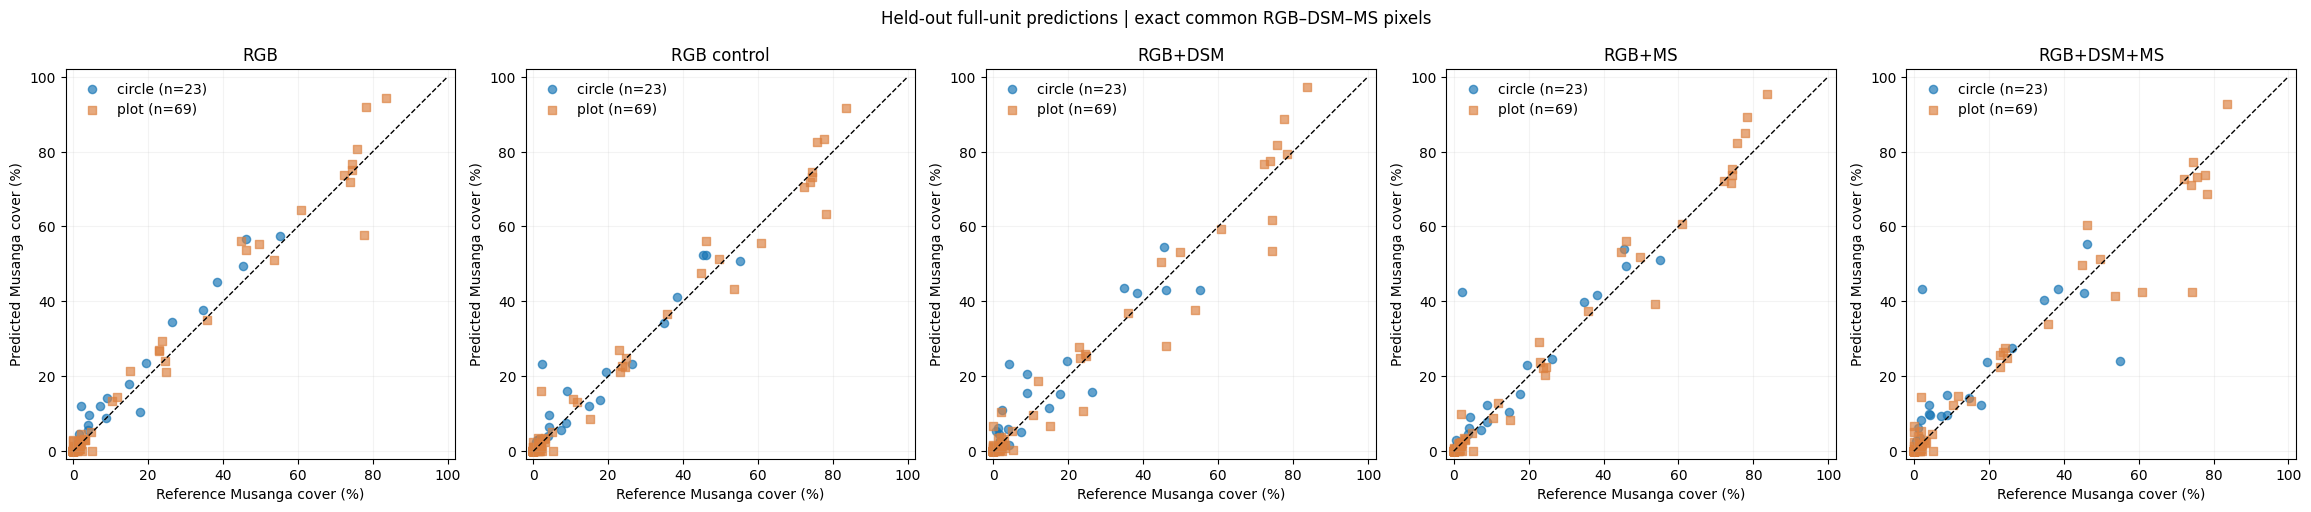

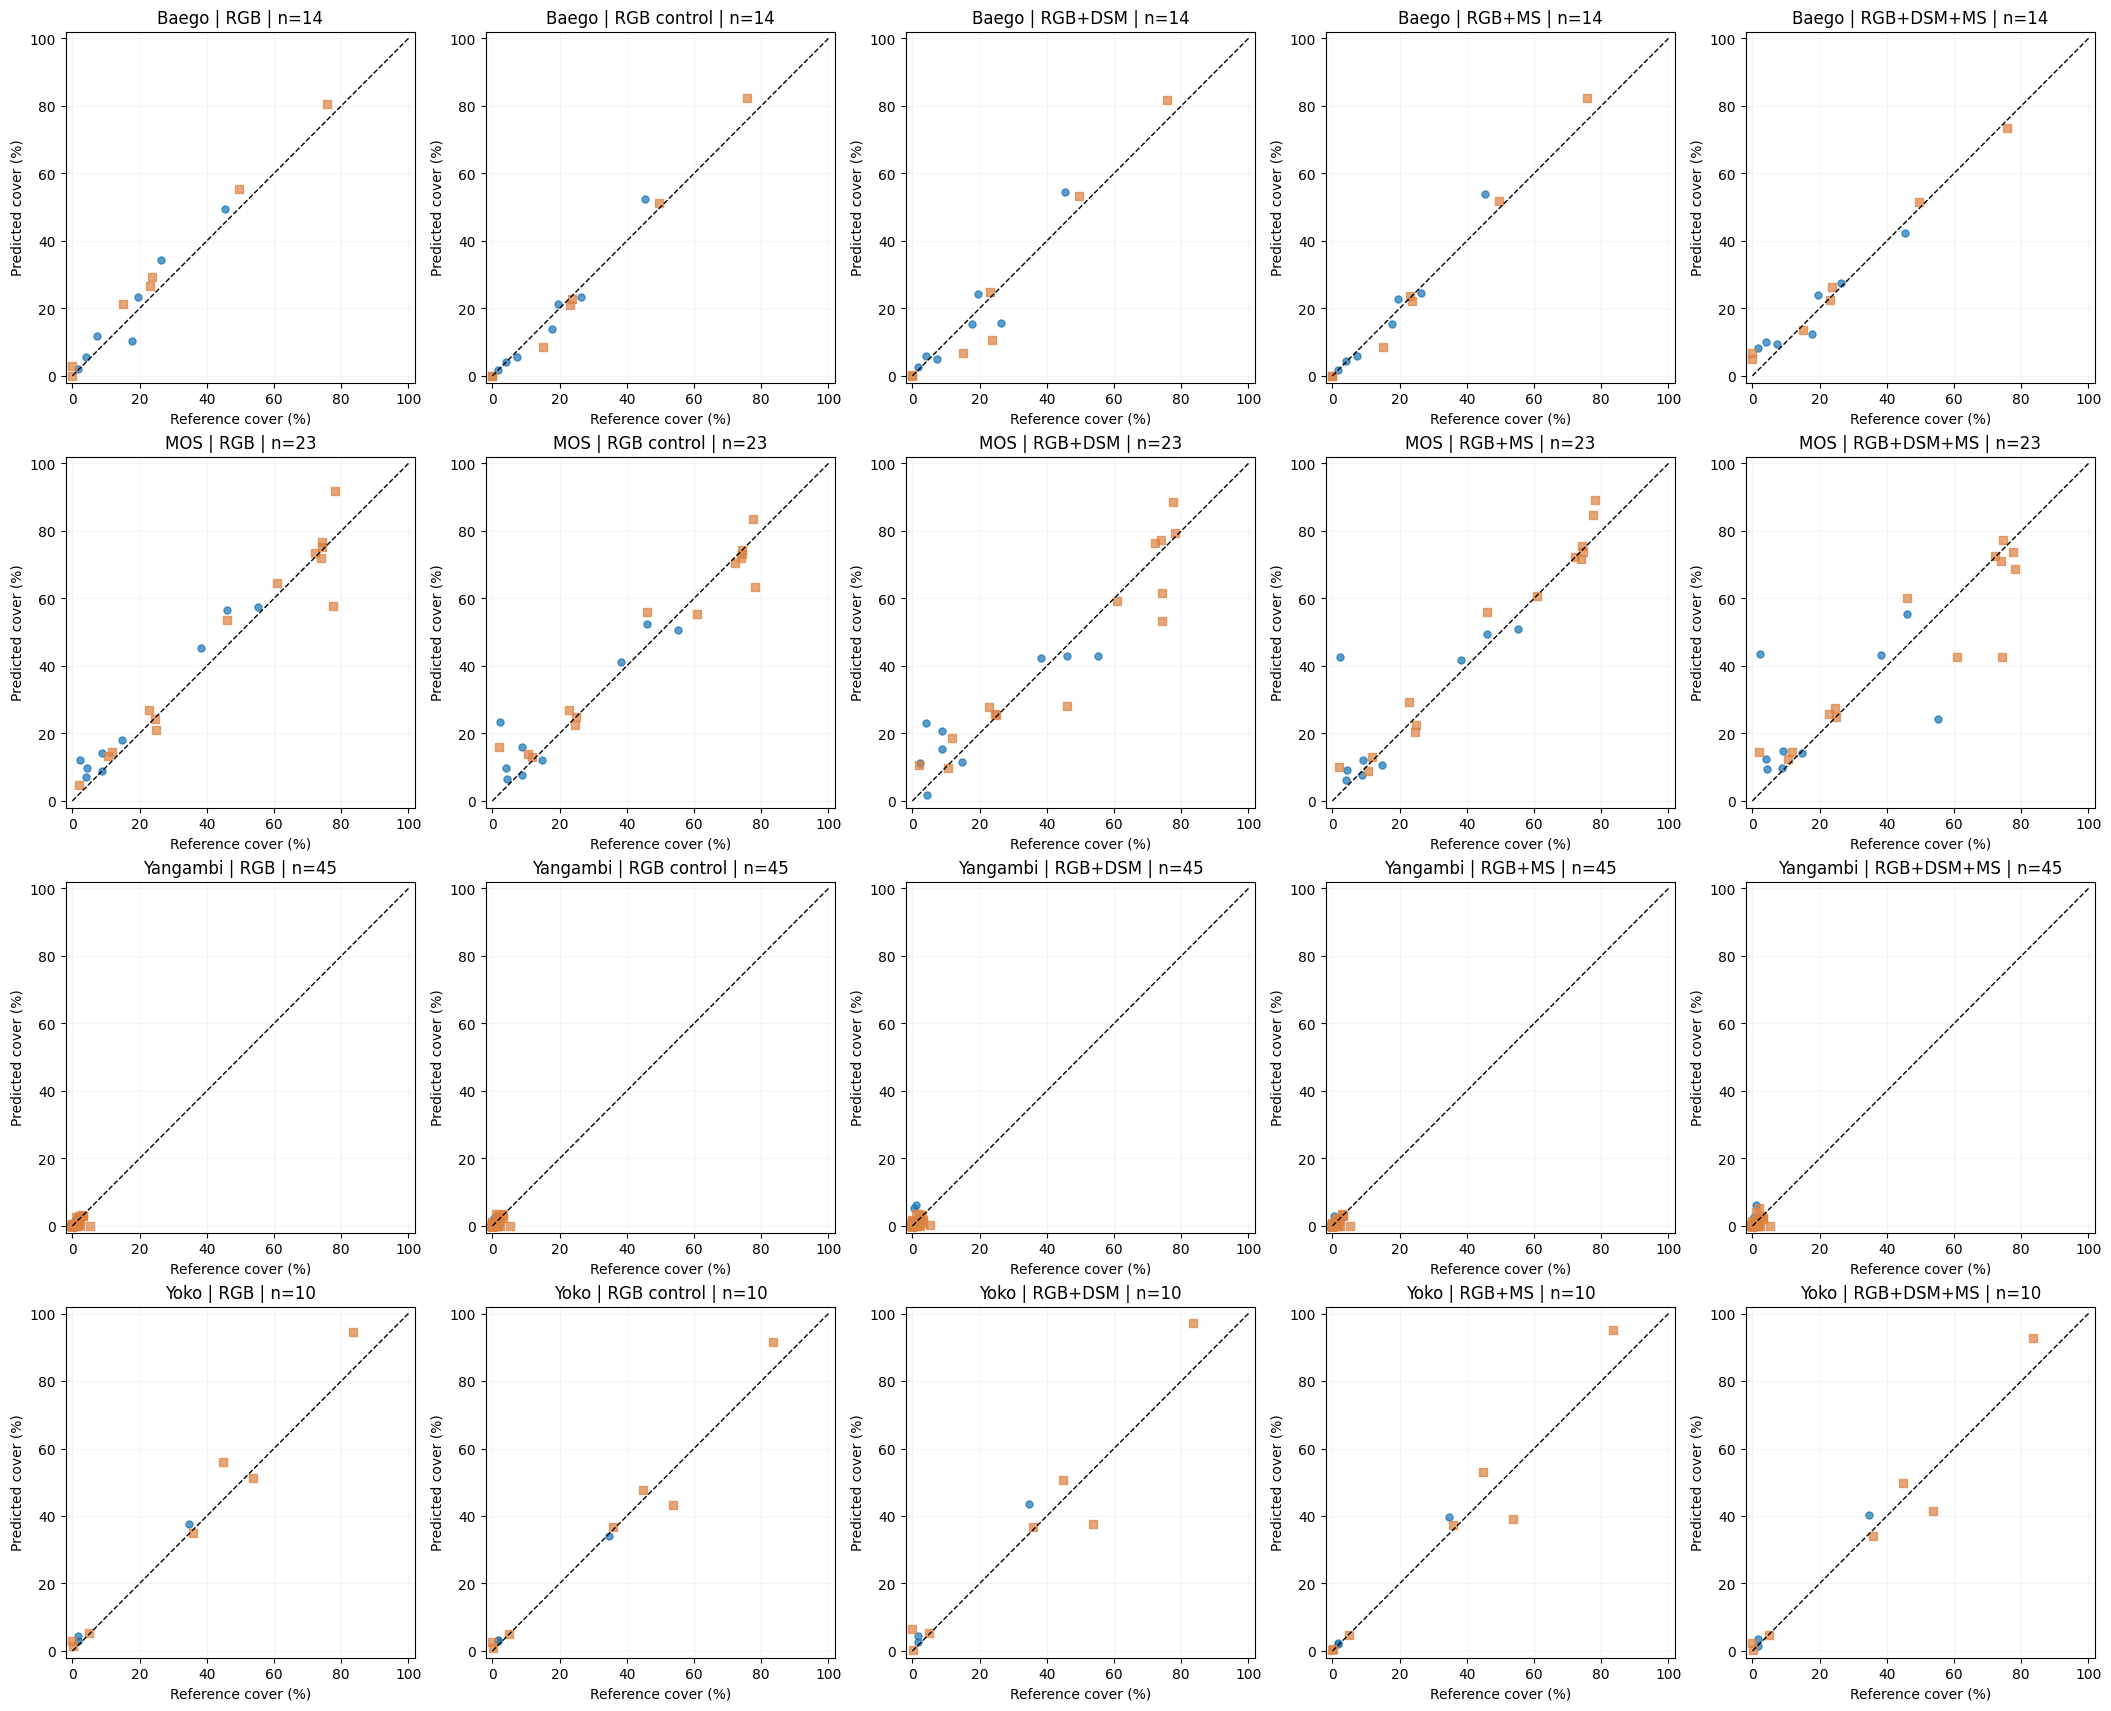

MOS high-cover >40%, including problematic units if they have complete MS support:


,site,model,cover_stratum,n,F1,IoU,Precision,Recall,R2,MAE_pp,RMSE_pp,Bias_pp,RPD,RPIQ,Brier
28,MOS,RGB,>40%,10,0.911,0.840,0.898,0.931,0.468,6.410,8.826,2.036,1.371,2.188,0.084
32,MOS,RGB control,>40%,10,0.916,0.849,0.921,0.916,0.694,5.176,6.699,-0.741,1.806,2.882,0.077
36,MOS,RGB+DSM,>40%,10,0.867,0.772,0.919,0.833,0.154,8.855,11.133,-4.866,1.087,1.734,0.114
40,MOS,RGB+DSM+MS,>40%,10,0.850,0.754,0.925,0.819,-0.850,12.417,16.458,-7.103,0.735,1.173,0.120
44,MOS,RGB+MS,>40%,10,0.929,0.870,0.914,0.948,0.793,3.964,5.505,2.505,2.198,3.507,0.071


,n,F1,IoU,Precision,Recall,R2,MAE_pp,RMSE_pp,Bias_pp,RPD,RPIQ,Brier,model,Group,Weighting
0,106,0.526,0.439,0.505,0.754,0.956,3.397,5.250,2.470,4.746,4.510,0.040,NB04 unified RGB,ALL full RGB only,NaN
1,92,0.545,0.461,0.559,0.741,0.968,2.521,4.307,1.414,5.603,5.435,0.032,RGB,ALL,Equal units
2,92,0.579,0.494,0.611,0.716,0.969,2.304,4.252,0.560,5.675,5.505,0.032,RGB control,ALL,Equal units
3,92,0.545,0.455,0.602,0.691,0.939,3.572,5.980,0.399,4.036,3.915,0.039,RGB+DSM,ALL,Equal units
4,92,0.503,0.422,0.551,0.693,0.899,3.671,7.650,0.562,3.154,3.060,0.040,RGB+DSM+MS,ALL,Equal units
5,92,0.584,0.503,0.616,0.742,0.947,2.436,5.540,1.074,4.356,4.226,0.031,RGB+MS,ALL,Equal units


COMPLETE NB05 report: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/V5/Outputs/05_rgb_dsm_ms_matched_v1


In [11]:

from sklearn.metrics import r2_score
from IPython.display import display
import matplotlib.pyplot as plt
rows=[];support=[]
for z in EVAL.itertuples(index=False):
    p=RESULT_DIR/f'f{int(z.fold)}_{z.unit_type}_{str(z.unit_id).replace("/","_")}.npz'
    assert p.is_file(),p
    with np.load(p,allow_pickle=False) as x:
        meta=json.loads(str(x['metadata'].item()))
        res=json.loads(str(x['results'].item()))
    support.append(meta)
    for mode,q in res.items():
        rows.append({**meta,'model':{'RGB':'RGB','CTRL':'RGB control','DSM':'RGB+DSM','MS':'RGB+MS','BOTH':'RGB+DSM+MS'}[mode],**q})
S=pd.DataFrame(support);RESULTS=pd.DataFrame(rows)
assert len(S)==106 and not S.duplicated(['unit_type','unit_id']).any()
S.to_csv(OUT/'06_all_106_unit_support.csv',index=False)
assert S.n_common.gt(0).any(),'No complete RGB+DSM+MS support; diagnose source registration'
ncommon=int(S.n_common.gt(0).sum())
assert len(RESULTS)==ncommon*5
for k,g in RESULTS.groupby(['unit_type','unit_id']):
    assert g.model.nunique()==5
    assert g.n_pixels.nunique()==1
    assert g.observed_cover_pp.max()-g.observed_cover_pp.min()<1e-9
RESULTS.to_csv(OUT/'06_all_five_models_matched_unit_metrics.csv',index=False)
print('FULL NB04 UNITS',len(BASELINE),'| COMMON-SUPPORT MATCHED UNITS',ncommon,'| ZERO COMMON SUPPORT',106-ncommon)
display(S.groupby(['site','unit_type']).agg(
    total=('n_common','size'),matched=('n_common',lambda v:int((v>0).sum())),
    common_pixels=('n_common','sum')))
print('Not all 106 units have the same source coverage; missing units are NOT zero predictions.')

# Copy NB04 exact weighted metrics definitions, independently of notebook globals
def wm(x,w):
    x=np.asarray(x,float);w=np.asarray(w,float)
    valid=np.isfinite(x)&np.isfinite(w)&(w>0)
    return float(np.average(x[valid],weights=w[valid])) if valid.any() else np.nan

def weighted_quantile(x,w,qs):
    x=np.asarray(x,float);w=np.asarray(w,float)
    valid=np.isfinite(x)&np.isfinite(w)&(w>0)
    x=x[valid];w=w[valid]
    if not len(x):return np.full(len(qs),np.nan)
    ix=np.argsort(x);x=x[ix];w=w[ix]
    c=(np.cumsum(w)-w/2)/w.sum()
    return np.interp(qs,c,x)

def weights(g,method):
    if method=='Equal units':return np.ones(len(g),float)
    if method=='Balanced circle/plot':
        n=g.unit_type.value_counts()
        return g.unit_type.map(lambda t:1/n[t]).to_numpy(float)
    if method=='Valid-pixel weighted':return g.n_pixels.to_numpy(float)
    raise ValueError(method)

def summarize(g,method):
    w=weights(g,method)
    obs=g.observed_cover_pp.to_numpy(float)
    pred=g.predicted_cover_pp.to_numpy(float)
    error=pred-obs
    mae=wm(np.abs(error),w)
    rmse=np.sqrt(wm(error**2,w))
    bias=wm(error,w)
    var=wm((obs-wm(obs,w))**2,w)
    sd=np.sqrt(var)
    q1,q3=weighted_quantile(obs,w,[.25,.75])
    # Weighted means of unit-level segmentation metrics (not pixel-pooled F1).
    result={'n':len(g),'F1':wm(g.F1,w),'IoU':wm(g.IoU,w),
            'Precision':wm(g.precision,w),'Recall':wm(g.recall,w),
            'R2':1-rmse**2/var if var>0 else np.nan,
            'MAE_pp':mae,'RMSE_pp':rmse,'Bias_pp':bias,
            'RPD':sd/rmse if rmse>0 else np.nan,
            'RPIQ':(q3-q1)/rmse if rmse>0 else np.nan,
            'Brier':wm(g.brier,w)}
    return result


SCHEMES=['Equal units','Valid-pixel weighted']
REPORT=[]
for (group,gg) in [('ALL',RESULTS),*list(RESULTS.groupby('site'))]:
    for model,g in gg.groupby('model'):
        for method in SCHEMES:
            REPORT.append(dict(Group=group,model=model,Weighting=method,
                               **summarize(g,method)))
REPORT=pd.DataFrame(REPORT)
REPORT.to_csv(OUT/'06_weighted_model_comparison.csv',index=False)
display(REPORT.query('Group == "ALL"').round(3))
print('PRIMARY — equal weight per reference footprint, per site:')
display(REPORT.query('Weighting == "Equal units"').round(3))

# Explicit paired improvement on exact same common-valid reference units.
P=RESULTS.pivot(index=['site','unit_type','unit_id','fold','spatial_group'],
                columns='model',
                values=['observed_cover_pp','predicted_cover_pp','F1','IoU','n_pixels'])
P.columns=['%s_%s'%(a,b) for a,b in P.columns]
P=P.reset_index()
p0=P['observed_cover_pp_RGB'].to_numpy(float)
for mode in ('RGB+DSM','RGB+MS','RGB+DSM+MS'):
    P['Delta_abs_cover_error_'+mode]=(
        np.abs(P['predicted_cover_pp_'+mode]-p0)
        -np.abs(P['predicted_cover_pp_RGB control']-p0))
P.to_csv(OUT/'06_paired_unit_differences.csv',index=False)

# Group bootstrap keeps spatial group dependence; does not treat pixels as independent.
rng=np.random.default_rng(20261119)
boot=[]
for mode in ('RGB+DSM','RGB+MS','RGB+DSM+MS'):
    g=P.copy()
    keys=g.spatial_group.unique()
    vals=[]
    for _ in range(1000):
        draw=rng.choice(keys,size=len(keys),replace=True)
        sampled=pd.concat([g[g.spatial_group.eq(t)] for t in draw],ignore_index=True)
        w=weights(sampled,'Equal units')
        vals.append(wm(sampled['Delta_abs_cover_error_'+mode],w))
    point=wm(g['Delta_abs_cover_error_'+mode],
             weights(g,'Equal units'))
    boot.append(dict(model=mode,delta_MAE_pp=point,
                     CI95_low=np.percentile(vals,2.5),
                     CI95_high=np.percentile(vals,97.5),n_units=len(g),
                     n_groups=len(keys)))
BOOT=pd.DataFrame(boot)
BOOT.to_csv(OUT/'06_spatial_group_bootstrap.csv',index=False)
print('Paired delta absolute cover error versus fine-tuned RGB control (negative = improvement)')
display(BOOT.round(3))

colors={'circle':'#1675B5','plot':'#DC8140'}
fig,axes=plt.subplots(1,5,figsize=(23,5),constrained_layout=True)
for ax,mode in zip(axes,('RGB','RGB control','RGB+DSM','RGB+MS','RGB+DSM+MS')):
    data=RESULTS[RESULTS.model.eq(mode)]
    for typ,part in data.groupby('unit_type'):
        ax.scatter(part.observed_cover_pp,part.predicted_cover_pp,
                   s=35,alpha=.67,c=colors[typ],
                   marker='o' if typ=='circle' else 's',
                   label=f'{typ} (n={len(part)})')
    ax.plot([0,100],[0,100],'k--',lw=1)
    ax.set(xlim=(-2,102),ylim=(-2,102),title=mode,
           xlabel='Reference Musanga cover (%)',
           ylabel='Predicted Musanga cover (%)')
    ax.set_aspect('equal',adjustable='box');ax.grid(alpha=.15);ax.legend(frameon=False)
fig.suptitle('Held-out full-unit predictions | exact common RGB–DSM–MS pixels')
fig.savefig(OUT/'06_three_arm_matched_scatter.png',dpi=210,bbox_inches='tight')
plt.show()

# Forest-specific scatterplots of three modalities.
fig,axs=plt.subplots(4,5,figsize=(21,17),constrained_layout=True)
sites=sorted(RESULTS.site.unique())
for i,site in enumerate(sites):
    for j,mode in enumerate(('RGB','RGB control','RGB+DSM','RGB+MS','RGB+DSM+MS')):
        ax=axs[i,j]
        d=RESULTS[(RESULTS.site.eq(site))&(RESULTS.model.eq(mode))]
        for typ,part in d.groupby('unit_type'):
            ax.scatter(part.observed_cover_pp,part.predicted_cover_pp,
                       color=colors[typ],alpha=.7,s=26,
                       marker='o' if typ=='circle' else 's')
        ax.plot([0,100],[0,100],'k--',lw=1)
        ax.set(xlim=(-2,102),ylim=(-2,102),
               title=f'{site} | {mode} | n={len(d)}',
               xlabel='Reference cover (%)',ylabel='Predicted cover (%)')
        ax.grid(alpha=.12)
fig.savefig(OUT/'06_three_arm_scatter_by_forest.png',dpi=180,bbox_inches='tight')
plt.show()

# Cover strata for high-cover MOS failure interpretation.
bins=[-.001,1,5,20,40,100.001]
labels=['0–1%','1–5%','5–20%','20–40%','>40%']
RESULTS['cover_stratum']=pd.cut(RESULTS.observed_cover_pp,bins=bins,
                               labels=labels,include_lowest=True)
COVER=[]
for (site,model,stratum),g in RESULTS.groupby(
        ['site','model','cover_stratum'],observed=True):
    COVER.append(dict(site=site,model=model,cover_stratum=str(stratum),
                      **summarize(g,'Equal units')))
COVER=pd.DataFrame(COVER)
COVER.to_csv(OUT/'06_cover_strata_by_site.csv',index=False)
print('MOS high-cover >40%, including problematic units if they have complete MS support:')
display(COVER[(COVER.site=='MOS')&(COVER.cover_stratum=='>40%')].round(3))

# Separate NB04 106-unit *full RGB* baseline from the matched-support RGB scores.
nb04=BASELINE.copy()
nb04_summary={**summarize(nb04,'Equal units'),
              'model':'NB04 unified RGB','Group':'ALL full RGB only','n':len(nb04)}
matched=REPORT[(REPORT.Group=='ALL')&(REPORT.Weighting=='Equal units')].copy()
display(pd.concat([pd.DataFrame([nb04_summary]),matched],ignore_index=True).round(3))
manifest=dict(schema='NB05_matched_v1',baseline_training_key=TRAIN['training_key'],
              original_nb04_units=106,matched_units=ncommon,
              arms=['RGB','RGB control','RGB+DSM10','RGB+MS4','RGB+DSM10+MS4'],
              note='Full NB04 RGB baseline is not on identical pixels as matched-sensor comparison.',
              exclusions=[],fusion_training_asymmetry='Frozen RGB benchmark; matched RGB control and fusion arms fine-tuned equally',primary_weighting='equal reference footprints as NB04 V5')
(OUT/'06_reporting_contract.json').write_text(json.dumps(manifest,indent=2))
print('COMPLETE NB05 report:',OUT)


## Interpretation

Assess incremental sensor value against the equally fine-tuned RGB control, not only the frozen RGB model. Report paired spatial-group bootstrap intervals for cover MAE, forest-specific bias, segmentation and abundance strata. Common support requires all three sensors, so findings do not automatically generalize to all 106 footprints. Sensor registration and radiometric differences remain limitations. The matched RGB inference procedure differs from NB04; do not interpret differences as training effects alone.


## 07 — MS-only input ablation (final supplementary experiment)
Three additional fold fits only. Same 92 common-support footprints, training/validation chips, masked BCE, schedule, relative MS bands and RGB-grid geometry as Section 04. The fold-specific RGB-supervised encoder/decoder initializes the model (first convolution adapted to four inputs), so this is an **MS-only inference/input ablation**, not an independently MS-trained model. The matched support includes RGB and DSM validity even though neither is fed to the model. Existing outputs preserved. Run 07A → 07B → 07C after Sections 00–06. No NB07/NB08 changes.


In [ ]:
# MS-only extension — isolate new models and results; never overwrite the original five-arm comparison.
# Four-band relative spectral values on the original RGB grid; no RGB or DSM predictor.
# The held-out fold RGB-trained backbone/decoder is transferred, with conv1 adapted
# to four channels by averaging its RGB kernels and scaling by 3/4.
# Thus this tests MS-only input with RGB-supervised initialization, not MS-only training from scratch.
EXT=OUT/'07_ms_only_extension';EXT.mkdir(exist_ok=True)
MS_MODE='MS_ONLY'
LEGACY_MODES=('RGB','CTRL','DSM','MS','BOTH')
MS_MODES=(*LEGACY_MODES,MS_MODE)
assert len(EVAL)==106 and len(RESULTS)==92*5
# Reuse same fit routine and sampling schedule without modifying previous training helpers.
# Adapt a copy of original model and dataset implementations via explicit definitions.
def ms_only_model(fold):
    net=smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=4,classes=1)
    original=model_unified(fold).state_dict()
    state=net.state_dict()
    for k,v in state.items():
        if k=='encoder.conv1.weight':
            assert v.shape[1]==4 and original[k].shape[1]==3
            v.copy_(original[k].mean(dim=1,keepdim=True).expand_as(v)*.75)
        else:
            assert k in original and v.shape==original[k].shape,k
            v.copy_(original[k])
    net.load_state_dict(state,strict=True)
    return net
class MSOnlyDataset(Dataset):
    def __init__(self,rows,augment):
        self.rows=rows;self.augment=augment
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        z=self.rows[i]
        x=z['ms'].astype('float32')
        assert x.shape==(4,256,256)
        y=z['y'].astype('float32');w=z['w'].astype('float32')
        if self.augment:
            k=int(torch.randint(4,(1,)).item())
            x=np.rot90(x,k,axes=(1,2));y=np.rot90(y,k);w=np.rot90(w,k)
            if torch.rand(())<.5:
                x=x[:,:,::-1];y=y[:,::-1];w=w[:,::-1]
        return tuple(torch.from_numpy(np.ascontiguousarray(a)) for a in (x,y,w))
def ms_fingerprint(fold):
    return hashlib.sha256(json.dumps(dict(
        version='ms_only_v1',base_train_key=TRAIN['training_key'],split=SPLIT_CONTRACT['csv_sha256'],
        fold=fold,epochs=EPOCHS,steps=STEPS,batch=BATCH,lr=LR,seed=SEED,
        init='fold_RGB_backbone_decoder_conv1_RGB_mean_times_3over4',
        channels=['red','green','red_edge','nir'],input='relative_band_sum_normalized',
        cache_fingerprints=sorted(CACHES[CACHES.fold.eq(fold)].fingerprint.tolist())),sort_keys=True).encode()).hexdigest()
def ms_path(fold):return EXT/f'fold{fold}_MS_ONLY_{ms_fingerprint(fold)[:18]}.pt'
def fit_ms_only(fold):
    dest=ms_path(fold);fingerprint=ms_fingerprint(fold)
    if dest.is_file():
        ck=torch.load(dest,map_location='cpu',weights_only=False)
        assert ck['fingerprint']==fingerprint and ck['complete'] and ck['fold']==fold
        print('REUSE MS-only',fold);return
    tr,va=read_joint_fold(fold)
    torch.manual_seed(SEED+fold)
    net=ms_only_model(fold).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    train_ds=MSOnlyDataset(tr,True)
    val_dl=DataLoader(MSOnlyDataset(va,False),batch_size=BATCH,shuffle=False,num_workers=0)
    rng=np.random.default_rng(SEED+fold)
    best=float('inf');best_state=None;best_epoch=0;hist=[]
    for epoch in range(EPOCHS):
        net.train();losses=[];t0=time.perf_counter()
        for step in range(STEPS):
            indexes=rng.integers(0,len(train_ds),size=BATCH)
            batch=[train_ds[int(k)] for k in indexes]
            x,y,w=[torch.stack([q[k] for q in batch]).to(DEVICE) for k in range(3)]
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',enabled=DEVICE=='cuda'):
                logits=net(x)[:,0];loss=masked_bce(logits,y,w)
            loss.backward();opt.step();losses.append(float(loss.detach().item()))
        val=validate(net,val_dl)
        hist.append(dict(fold=fold,mode=MS_MODE,epoch=epoch+1,train_loss=np.mean(losses),inner_val_BCE=val,seconds=time.perf_counter()-t0))
        if val<best:
            best=val;best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
        print('TRAIN MS-only',fold,epoch+1,'/',EPOCHS,'train',round(np.mean(losses),4),'val',round(val,4),flush=True)
    assert best_state is not None
    tmp=dest.with_name(dest.name+'.tmp')
    torch.save(dict(fingerprint=fingerprint,complete=True,fold=fold,mode=MS_MODE,
                    baseline_training_key=TRAIN['training_key'],state=best_state,best_epoch=best_epoch,best_val_BCE=best,history=hist),tmp)
    os.replace(tmp,dest)
    pd.DataFrame(hist).to_csv(EXT/f'fold{fold}_MS_ONLY_history.csv',index=False)
    del net,opt,tr,va,train_ds,val_dl,best_state;gc.collect();torch.cuda.empty_cache()
for fold in range(3):fit_ms_only(fold)


In [ ]:
# 07B — Recompute joint validity using the identical NB05 inference recipe.
# No inference for existing RGB/fusion models; compare all reference support counts
# and observed cover against original per-unit files. Old cache did not retain mask
# pixels, so count/positive-count equivalence is the strongest available check.
@torch.inference_mode()
def infer_ms_only(ds,dsm,vrts,unit_geom,models,mu,sd):
    geom=to_ds_geom(unit_geom,ds)
    bounds=rasterio.windows.from_bounds(*geom.bounds,transform=ds.transform)
    row0=max(0,int(np.floor(bounds.row_off))-TILE)
    col0=max(0,int(np.floor(bounds.col_off))-TILE)
    row1=min(ds.height,int(np.ceil(bounds.row_off+bounds.height))+TILE)
    col1=min(ds.width,int(np.ceil(bounds.col_off+bounds.width))+TILE)
    h=row1-row0;ww=col1-col0
    assert h>0 and ww>0 and h*ww<75_000_000,(h,ww)
    sums={mode:np.zeros((h,ww),np.float32) for mode in models}
    weights=np.zeros((h,ww),np.float32)
    # Tracks agreement that every contributing tile has all auxiliary data valid.
    valid_weight=np.zeros((h,ww),np.float32)
    all_tile_windows=[
        Window(col0+c,row0+r,min(TILE,ww-c),min(TILE,h-r))
        for r in origins(h) for c in origins(ww)]
    provider=SharedContextProvider(ds,dsm,all_tile_windows)
    check_shared_context(provider,str(ds.name),all_tile_windows,n_test=2)
    batch=[]
    def flush():
        if not batch:return
        inp={
            'RGB':torch.from_numpy(np.stack([q['rgb'] for q in batch])).float().to(DEVICE)/255.,
            'DSM':torch.from_numpy(np.stack([q['dsm'] for q in batch])).float().to(DEVICE),
            'MS':torch.from_numpy(np.stack([q['ms'] for q in batch])).float().to(DEVICE)
        }
        inp={MS_MODE:inp['MS'][:,3:]}
        for mode,net in models.items():
            with torch.autocast('cuda',enabled=DEVICE=='cuda'):
                probs=torch.sigmoid(net(inp[mode])[:,0]).float().cpu().numpy()
            for rec,p in zip(batch,probs):
                r,c,hh,wwi=rec['loc']
                sums[mode][r:r+hh,c:c+wwi]+=p[:hh,:wwi]*HANN[:hh,:wwi]
        for rec in batch:
            r,c,hh,wwi=rec['loc']
            kern=HANN[:hh,:wwi]
            weights[r:r+hh,c:c+wwi]+=kern
            valid_weight[r:r+hh,c:c+wwi]+=kern*rec['joint'][:hh,:wwi]
        batch.clear()

    for r in origins(h):
        for c in origins(ww):
            hh=min(TILE,h-r);wi=min(TILE,ww-c)
            win=Window(col0+c,row0+r,wi,hh)
            rgb_data,rgb_ok=rgb_read(ds,win)
            dsm13,dsm_ok=multiscale_tile(ds,dsm,win,provider)
            ms4,ms_ok,flight=choose_complete_flight(vrts,win)
            joint=rgb_ok&dsm_ok&ms_ok
            nr=np.zeros((3,TILE,TILE),np.uint8)
            nd=np.zeros((13,TILE,TILE),np.float32)
            nm=np.zeros((7,TILE,TILE),np.float32)
            nr[:,:hh,:wi]=rgb_data.transpose(2,0,1)
            nd[:3,:hh,:wi]=nr[:,:hh,:wi].astype('float32')/255.
            nd[3:,:hh,:wi]=np.clip(
                (dsm13[3:]-mu[:,None,None])/sd[:,None,None],-6,6)
            nm[:3,:hh,:wi]=nd[:3,:hh,:wi]
            nm[3:,:hh,:wi]=ms4
            batch.append(dict(rgb=nr,dsm=nd,ms=nm,loc=(r,c,hh,wi),joint=joint))
            if len(batch)>=BATCH_INFER:flush()
    flush()
    assert weights.min()>0
    preds={mode:np.clip(sums[mode]/weights,0,1) for mode in sums}
    common=(valid_weight>=weights-1e-5)
    win=Window(col0,row0,ww,h)
    x,rv=rgb_read(ds,win)
    footprint=burn(geom,ds,win)
    roi=burn(to_ds_geom(ROI_GEOM,ds),ds,win)
    common&=rv&footprint&roi
    return preds,common,win

MS_RESULT_DIR=EXT/'per_unit';MS_RESULT_DIR.mkdir(exist_ok=True)
for fold in range(3):
    ck=torch.load(ms_path(fold),map_location='cpu',weights_only=False)
    assert ck['fingerprint']==ms_fingerprint(fold) and ck['complete']
    net=ms_only_model(fold);net.load_state_dict(ck['state'],strict=True);net=net.to(DEVICE).eval()
    # Normalization retained for exact common-support routine; DSM is NOT model input.
    ctrl=torch.load(MODEL_DIR/f'fold{fold}_RGB_CTRL_v1.pt',map_location='cpu',weights_only=False)
    assert ctrl['complete'] and ctrl['baseline_training_key']==TRAIN['training_key']
    mu,sd=np.array(ctrl['norm_mean']),np.array(ctrl['norm_std'])
    for z in EVAL[EVAL.fold.eq(fold)].itertuples(index=False):
        stem=f'f{fold}_{z.unit_type}_{str(z.unit_id).replace("/","_")}.npz'
        original_path=RESULT_DIR/stem
        assert original_path.is_file()
        oldsha=hashlib.sha256(original_path.read_bytes()).hexdigest()
        key=hashlib.sha256((ck['fingerprint']+oldsha).encode()).hexdigest()
        with np.load(original_path,allow_pickle=False) as a:
            meta=json.loads(str(a['metadata'].item()));old=json.loads(str(a['results'].item()))
        assert meta['unit_id']==str(z.unit_id) and meta['fold']==fold
        dest=MS_RESULT_DIR/stem
        if dest.is_file():
            with np.load(dest,allow_pickle=False) as a:
                assert str(a['fingerprint'].item())==key
                assert json.loads(str(a['metadata'].item()))==meta
            print('REUSE MS-only inference',z.site,z.unit_id,flush=True);continue
        report={}
        if meta['n_common']>0:
            with ExitStack() as stack:
                ds=stack.enter_context(rasterio.open(MOSAICS[z.mosaic]))
                dsm=stack.enter_context(rasterio.open(DSM_BY_MOSAIC[z.mosaic]))
                vrts=mosaic_ms_vrts(ds,stack,z.mosaic)
                preds,common,win=infer_ms_only(ds,dsm,vrts,REF_UNITS[(str(z.unit_type),str(z.unit_id))],{MS_MODE:net},mu,sd)
                truth,supervised=truth_mask(str(z.unit_type),ds,win,common)
                y=truth[supervised].astype('uint8')
                assert len(y)==meta['n_common']==old['RGB']['n_pixels'],('Common support changed',z.unit_id)
                assert int(y.sum())==old['RGB']['n_pos'],('Observed positive pixels changed',z.unit_id)
                assert int((y==0).sum())==old['RGB']['n_neg']
                score,*_=scores(y,preds[MS_MODE][supervised])
                assert abs(score['observed_cover_pp']-old['RGB']['observed_cover_pp'])<1e-9
                report[MS_MODE]=score
        else:
            assert not old,('Unexpected legacy predictions for excluded unit',z.unit_id)
        tmp=dest.with_name(dest.name+'.tmp.npz')
        np.savez_compressed(tmp,fingerprint=np.array(key),metadata=np.array(json.dumps(meta)),results=np.array(json.dumps(report,default=json_default)))
        os.replace(tmp,dest)
        print('MS-only COMPLETE',z.site,z.unit_id,'common pixels',meta['n_common'],flush=True)
    del net,ck,ctrl;gc.collect();torch.cuda.empty_cache()
print('MS-only held-out inference complete.')


In [ ]:
# 07C — Six-arm report, original five-arm outputs untouched.
original=pd.read_csv(OUT/'06_all_five_models_matched_unit_metrics.csv')
assert len(original)==460
ms_rows=[]
for z in EVAL.itertuples(index=False):
    stem=f'f{int(z.fold)}_{z.unit_type}_{str(z.unit_id).replace("/","_")}.npz'
    with np.load(MS_RESULT_DIR/stem,allow_pickle=False) as a:
        meta=json.loads(str(a['metadata'].item()));res=json.loads(str(a['results'].item()))
    if meta['n_common']>0:
        ms_rows.append({**meta,'model':'MS only',**res[MS_MODE]})
six=pd.concat([original,pd.DataFrame(ms_rows)],ignore_index=True)
assert len(six)==552
for k,g in six.groupby(['unit_type','unit_id']):
    assert len(g)==6 and g.model.nunique()==6 and g.n_pixels.nunique()==1 and g.n_pos.nunique()==1
    assert g.observed_cover_pp.max()-g.observed_cover_pp.min()<1e-9
six.to_csv(EXT/'06_all_six_models_matched_unit_metrics.csv',index=False)
report=[]
for group,gg in [('ALL',six),*list(six.groupby('site'))]:
    for model,g in gg.groupby('model'):
        for scheme in ['Equal units','Valid-pixel weighted']:
            report.append(dict(Group=group,model=model,Weighting=scheme,**summarize(g,scheme)))
report=pd.DataFrame(report);report.to_csv(EXT/'06_weighted_model_comparison_six.csv',index=False)
display(report.query('Group == "ALL" and Weighting == "Equal units"').round(3))
display(report.query('Group != "ALL" and Weighting == "Equal units"').round(3))
p=six.pivot(index=['site','unit_type','unit_id','fold','spatial_group'],columns='model',values='abs_cover_error_pp').reset_index()
contrasts=[('MS only','RGB control'),('MS only','RGB'),('RGB+MS','MS only'),('RGB+MS','RGB control'),('RGB+DSM','RGB control'),('RGB+DSM+MS','RGB control')]
boot=[];groups=p.groupby(['site','spatial_group'],sort=True)
# Group-bootstrap, same draws for all contrasts. Equal footprint weighting.
keys=list(groups.groups);rng=np.random.default_rng(SEED);draw=rng.integers(0,len(keys),(1000,len(keys)))
for arm,reference in contrasts:
    p['delta']=p[arm]-p[reference]
    a=p.groupby(['site','spatial_group'],sort=True).delta.agg(['sum','count']).to_numpy(float)
    d=a[draw].sum(axis=1);v=d[:,0]/d[:,1]
    boot.append(dict(model=arm,reference=reference,delta_MAE_pp=p.delta.mean(),CI95_low=np.quantile(v,.025),CI95_high=np.quantile(v,.975),n_units=len(p),n_groups=len(keys)))
boot=pd.DataFrame(boot);boot.to_csv(EXT/'06_paired_spatial_group_bootstrap_six.csv',index=False);display(boot.round(3))
order=['RGB','RGB control','MS only','RGB+MS','RGB+DSM','RGB+DSM+MS']
fig,axs=plt.subplots(2,3,figsize=(12,8),layout='constrained')
for ax,mode in zip(axs.ravel(),order):
    g=six[six.model.eq(mode)];a=report[(report.Group=='ALL')&(report.Weighting=='Equal units')&(report.model==mode)].iloc[0]
    for typ,h in g.groupby('unit_type'):
        ax.scatter(h.observed_cover_pp,h.predicted_cover_pp,s=25,alpha=.65,c=colors[typ],marker='o' if typ=='circle' else 's',label=typ)
    ax.plot([0,100],[0,100],'k--',lw=1)
    ax.set(xlim=(0,100),ylim=(0,100),aspect='equal',xlabel='Reference cover (%)',ylabel='Predicted cover (%)',title=mode)
    ax.text(.04,.96,f'R² = {a.R2:.3f} | MAE = {a.MAE_pp:.2f} pp',transform=ax.transAxes,va='top',fontsize=9,bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
axs.flat[0].legend(fontsize=8,loc='lower right')
fig.suptitle('UAV sensor ablation — 92 matched held-out footprints');fig.savefig(EXT/'06_six_arm_matched_scatter.png',dpi=230);plt.show();plt.close(fig)
fig,axs=plt.subplots(4,6,figsize=(22,15),layout='constrained')
for i,site in enumerate(sorted(six.site.unique())):
    for j,mode in enumerate(order):
        ax=axs[i,j];g=six[(six.site==site)&(six.model==mode)]
        for typ,h in g.groupby('unit_type'):
            ax.scatter(h.observed_cover_pp,h.predicted_cover_pp,s=18,alpha=.65,c=colors[typ],marker='o' if typ=='circle' else 's')
        ax.plot([0,100],[0,100],'k--',lw=1);ax.set(xlim=(0,100),ylim=(0,100),aspect='equal',title=f'{site} — {mode}',xlabel='Observed (%)',ylabel='Predicted (%)')
fig.savefig(EXT/'06_six_arm_scatter_by_forest.png',dpi=200);plt.show();plt.close(fig)
six['cover_stratum']=pd.cut(six.observed_cover_pp,bins=[-.001,1,5,20,40,100.001],labels=['0–1%','1–5%','5–20%','20–40%','>40%'],include_lowest=True)
strata=pd.DataFrame([dict(site=site,model=model,cover_stratum=str(st),**summarize(g,'Equal units')) for (site,model,st),g in six.groupby(['site','model','cover_stratum'],observed=True)])
strata.to_csv(EXT/'06_cover_strata_by_site_six.csv',index=False)
manifest=dict(schema='NB05_ms_only_extension_v1',complete=True,matched_units=92,original_arms_preserved=True,arms=order,checkpoints=[str(ms_path(k)) for k in range(3)],initialization='fold-specific RGB-supervised U-Net; mean RGB first-layer kernels repeated across 4 channels and scaled 3/4',input='four relative MS channels; no RGB/DSM predictors',support='same inference recipe and original per-unit valid/positive/negative counts verified; original pixel masks not stored',primary_weighting='equal footprints',new_fits=3,production_changed=False)
(EXT/'06_ms_only_reporting_contract.json').write_text(json.dumps(manifest,indent=2))
print('COMPLETE MS-only extension:',EXT)
